# **New York City Yellow Taxi Data**

## Objective
In this case study you will be learning exploratory data analysis (EDA) with the help of a dataset on yellow taxi rides in New York City. This will enable you to understand why EDA is an important step in the process of data science and machine learning.

## **Problem Statement**
As an analyst at an upcoming taxi operation in NYC, you are tasked to use the 2023 taxi trip data to uncover insights that could help optimise taxi operations. The goal is to analyse patterns in the data that can inform strategic decisions to improve service efficiency, maximise revenue, and enhance passenger experience.

## Tasks
You need to perform the following steps for successfully completing this assignment:
1. Data Loading
2. Data Cleaning
3. Exploratory Analysis: Bivariate and Multivariate
4. Creating Visualisations to Support the Analysis
5. Deriving Insights and Stating Conclusions

---

**NOTE:** The marks given along with headings and sub-headings are cumulative marks for those particular headings/sub-headings.<br>

The actual marks for each task are specified within the tasks themselves.

For example, marks given with heading *2* or sub-heading *2.1* are the cumulative marks, for your reference only. <br>

The marks you will receive for completing tasks are given with the tasks.

Suppose the marks for two tasks are: 3 marks for 2.1.1 and 2 marks for 3.2.2, or
* 2.1.1 [3 marks]
* 3.2.2 [2 marks]

then, you will earn 3 marks for completing task 2.1.1 and 2 marks for completing task 3.2.2.


---

## Data Understanding
The yellow taxi trip records include fields capturing pick-up and drop-off dates/times, pick-up and drop-off locations, trip distances, itemized fares, rate types, payment types, and driver-reported passenger counts.

The data is stored in Parquet format (*.parquet*). The dataset is from 2009 to 2024. However, for this assignment, we will only be using the data from 2023.

The data for each month is present in a different parquet file. You will get twelve files for each of the months in 2023.

The data was collected and provided to the NYC Taxi and Limousine Commission (TLC) by technology providers like vendors and taxi hailing apps. <br>

You can find the link to the TLC trip records page here: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

###  Data Description
You can find the data description here: [Data Dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

**Trip Records**



|Field Name       |description |
|:----------------|:-----------|
| VendorID | A code indicating the TPEP provider that provided the record. <br> 1= Creative Mobile Technologies, LLC; <br> 2= VeriFone Inc. |
| tpep_pickup_datetime | The date and time when the meter was engaged.  |
| tpep_dropoff_datetime | The date and time when the meter was disengaged.   |
| Passenger_count | The number of passengers in the vehicle. <br> This is a driver-entered value. |
| Trip_distance | The elapsed trip distance in miles reported by the taximeter. |
| PULocationID | TLC Taxi Zone in which the taximeter was engaged |
| DOLocationID | TLC Taxi Zone in which the taximeter was disengaged |
|RateCodeID |The final rate code in effect at the end of the trip.<br> 1 = Standard rate <br> 2 = JFK <br> 3 = Newark <br>4 = Nassau or Westchester <br>5 = Negotiated fare <br>6 = Group ride |
|Store_and_fwd_flag |This flag indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.  <br>Y= store and forward trip <br>N= not a store and forward trip |
|Payment_type| A numeric code signifying how the passenger paid for the trip. <br> 1 = Credit card <br>2 = Cash <br>3 = No charge <br>4 = Dispute <br>5 = Unknown <br>6 = Voided trip |
|Fare_amount| The time-and-distance fare calculated by the meter. <br>Extra Miscellaneous extras and surcharges.  Currently, this only includes the 0.50 and 1 USD rush hour and overnight charges. |
|MTA_tax |0.50 USD MTA tax that is automatically triggered based on the metered rate in use. |
|Improvement_surcharge | 0.30 USD improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015. |
|Tip_amount |Tip amount – This field is automatically populated for credit card tips. Cash tips are not included. |
| Tolls_amount | Total amount of all tolls paid in trip.  |
| total_amount | The total amount charged to passengers. Does not include cash tips. |
|Congestion_Surcharge |Total amount collected in trip for NYS congestion surcharge. |
| Airport_fee | 1.25 USD for pick up only at LaGuardia and John F. Kennedy Airports|

Although the amounts of extra charges and taxes applied are specified in the data dictionary, you will see that some cases have different values of these charges in the actual data.

**Taxi Zones**

Each of the trip records contains a field corresponding to the location of the pickup or drop-off of the trip, populated by numbers ranging from 1-263.

These numbers correspond to taxi zones, which may be downloaded as a table or map/shapefile and matched to the trip records using a join.

This is covered in more detail in later sections.

---

## **1** Data Preparation

<font color = red>[5 marks]</font> <br>

### Import Libraries

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Install libraries first
# Install the versions needed
!pip install -q --force-reinstall \
    numpy==1.26.4 \
    pandas==2.2.2 \
    matplotlib==3.10.0 \
    seaborn==0.13.2

# Automatically restart the session to fix the ValueError(For google colab only)
import os
os.kill(os.getpid(), 9)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.5/117.5 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 73.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 96.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 96.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 362.6/362.6 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 73.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.2/100.2 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 80.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.8/122.8 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 229.9/2

In [1]:
# Import warnings
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Import the libraries you will be using for analysis
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
%matplotlib inline

In [3]:
# Recommended versions
# numpy version: 1.26.4
# pandas version: 2.2.2
# matplotlib version: 3.10.0
# seaborn version: 0.13.2

# Check versions
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 1.26.4
pandas version: 2.2.2
matplotlib version: 3.10.0
seaborn version: 0.13.2


### **1.1** Load the dataset
<font color = red>[5 marks]</font> <br>

You will see twelve files, one for each month.

To read parquet files with Pandas, you have to follow a similar syntax as that for CSV files.

`df = pd.read_parquet('file.parquet')`

In [ ]:
# Try loading one file

#df = pd.read_parquet('/content/drive/MyDrive/NYC Assignment/trip_records/2023-1.parquet')
#df.info()

# Check the number of rows
#print(f"Total Rows: {len(df):,}")
#print(f"Dataset Shape: {df.shape}")

How many rows are there? Do you think handling such a large number of rows is computationally feasible when we have to combine the data for all twelve months into one?

To handle this, we need to sample a fraction of data from each of the files. How to go about that? Think of a way to select only some portion of the data from each month's file that accurately represents the trends.

#### Sampling the Data
> One way is to take a small percentage of entries for pickup in every hour of a date. So, for all the days in a month, we can iterate through the hours and select 5% values randomly from those. Use `tpep_pickup_datetime` for this. Separate date and hour from the datetime values and then for each date, select some fraction of trips for each of the 24 hours.

To sample data, you can use the `sample()` method. Follow this syntax:

```Python
# sampled_data is an empty DF to keep appending sampled data of each hour
# hour_data is the DF of entries for an hour 'X' on a date 'Y'

sample = hour_data.sample(frac = 0.05, random_state = 42)
# sample 0.05 of the hour_data
# random_state is just a seed for sampling, you can define it yourself

sampled_data = pd.concat([sampled_data, sample]) # adding data for this hour to the DF
```

This *sampled_data* will contain 5% values selected at random from each hour.

Note that the code given above is only the part that will be used for sampling and not the complete code required for sampling and combining the data files.

Keep in mind that you sample by date AND hour, not just hour. (Why?)

---

**1.1.1** <font color = red>[5 marks]</font> <br>
Figure out how to sample and combine the files.

**Note:** It is not mandatory to use the method specified above. While sampling, you only need to make sure that your sampled data represents the overall data of all the months accurately.

In [ ]:
# Sample the data
# It is recommmended to not load all the files at once to avoid memory overload

In [ ]:
# Already done in import section
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
# Take a small percentage of entries from each hour of every date.
# Iterating through the monthly data:
# read a month file -> day -> hour: append sampled data -> move to next hour -> move to next day after 24 hours -> move to next month file
# Create a single dataframe for the year combining all the monthly data

# Select the folder having data files
import os

os.chdir('/content/drive/MyDrive/NYC Assignment/trip_records')

# Create a list of all the twelve files to read
file_list = [f for f in os.listdir() if f.endswith('.parquet')]

# initialise an empty dataframe
df = pd.DataFrame()


# iterate through the list of files and sample one by one:
for file_name in file_list:
    try:

        # file path for the current file
        file_path = os.path.join(os.getcwd(), file_name)

        # Reading the current file
        print(f"Processing {file_name}...")
        month_data = pd.read_parquet(file_path)

        # extracting day and hour for grouping
        month_data['pickup_day'] = month_data['tpep_pickup_datetime'].dt.date
        month_data['pickup_hour'] = month_data['tpep_pickup_datetime'].dt.hour

        # temporary dataframe to collect samples for this file
        sampled_data = pd.DataFrame()

        # Loop through dates and then loop through every hour of each date
        for day in month_data['pickup_day'].unique():
            day_subset = month_data[month_data['pickup_day'] == day]

            # Iterate through each hour of the selected date
            for hr in range(24):
                hour_subset = day_subset[day_subset['pickup_hour'] == hr]

                if len(hour_subset) == 0:
                    continue

                # Sample 5%
                sample = hour_subset.sample(frac=0.05, random_state=42)

                # add data of this hour to the dataframe
                sampled_data = pd.concat([sampled_data, sample], ignore_index=True)

        # Concatenate the sampled data of all the dates to a single dataframe
        df = pd.concat([df, sampled_data], ignore_index=True)

    except Exception as e:
        print(f"Error reading file {file_name}: {e}")

Processing 2023-9.parquet...
Processing 2023-5.parquet...
Processing 2023-6.parquet...
Processing 2023-2.parquet...
Processing 2023-1.parquet...
Processing 2023-8.parquet...
Processing 2023-7.parquet...
Processing 2023-10.parquet...
Processing 2023-3.parquet...
Processing 2023-12.parquet...
Processing 2023-4.parquet...
Processing 2023-11.parquet...


After combining the data files into one DataFrame, convert the new DataFrame to a CSV or parquet file and store it to use directly.

Ideally, you can try keeping the total entries to around 250,000 to 300,000.

In [ ]:
# Store the df in csv/parquet
df.to_parquet('sampled_nyc_taxi_2023.parquet')
df.to_csv('sampled_nyc_taxi_2023.csv')
print(f'   Total rows : {len(df):,}')
print(f'   Columns    : {df.columns.tolist()}')
print(f'   Shape: {df.shape}')

   Total rows : 1,896,400
   Columns    : ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'pickup_day', 'pickup_hour', 'airport_fee']
   Shape: (1896400, 22)


## **2** Data Cleaning
<font color = red>[30 marks]</font> <br>

Now we can load the new data directly.

In [ ]:
# Load the new data file

df = pd.read_parquet('/content/drive/MyDrive/NYC Assignment/sampled_nyc_taxi_2023.parquet')

In [ ]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,pickup_day,pickup_hour,airport_fee
0,2,2023-09-01 00:39:59,2023-09-01 01:00:28,NaN,4.71,NaN,None,113,238,0,24.83,0.00,0.50,4.32,0.00,1.00,33.15,NaN,NaN,2023-09-01,0,NaN
1,2,2023-09-01 00:24:50,2023-09-01 00:27:19,2.00,0.56,1.00,N,142,142,2,5.10,1.00,0.50,0.00,0.00,1.00,10.10,2.50,0.00,2023-09-01,0,NaN
2,2,2023-09-01 00:19:27,2023-09-01 01:04:02,2.00,18.46,2.00,N,132,163,1,70.00,0.00,0.50,15.71,6.94,1.00,98.40,2.50,1.75,2023-09-01,0,NaN
3,2,2023-09-01 00:42:13,2023-09-01 01:20:20,2.00,13.71,1.00,N,249,180,4,59.70,1.00,0.50,0.00,0.00,1.00,64.70,2.50,0.00,2023-09-01,0,NaN
4,2,2023-09-01 00:11:38,2023-09-01 00:17:56,1.00,0.71,1.00,N,144,232,1,7.90,1.00,0.50,2.00,0.00,1.00,14.90,2.50,0.00,2023-09-01,0,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1896400 entries, 0 to 1896399
Data columns (total 22 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

#### **2.1** Fixing Columns
<font color = red>[10 marks]</font> <br>

Fix/drop any columns as you seem necessary in the below sections

**2.1.1** <font color = red>[2 marks]</font> <br>

Fix the index and drop unnecessary columns

In [ ]:
# Fix the index and drop any columns that are not needed
df.reset_index(drop=True, inplace=True)
# The sampling loop added two helper columns. These were only needed during sampling so we drop them now.
df.drop(columns=['pickup_day','pickup_hour'], inplace=True)


In [ ]:
#df.head()

**2.1.2** <font color = red>[3 marks]</font> <br>
There are two airport fee columns. This is possibly an error in naming columns. Let's see whether these can be combined into a single column.

In [ ]:
# Checking which column has more NaN values
a = df['Airport_fee'].isna().sum()
b = df['airport_fee'].isna().sum()
print(f'Airport_fee: {a}')
print(f'airport_fee: {b}')

Airport_fee: 213357
airport_fee: 1747917


In [ ]:
# Combine the two airport fee columns
#checking if both are ever non-null for the same row
((~df['Airport_fee'].isna()) & (~df['airport_fee'].isna())).sum()

# taking Airport_fee first, since it has less Nan values; wherever it is NaN, take value from airport_fee
df['airport_fee'] = df['Airport_fee'].fillna(df['airport_fee'])
df.drop(columns=['Airport_fee'], inplace=True)

In [ ]:
#df.info()
#df.head()

**2.1.3** <font color = red>[5 marks]</font> <br>
Fix columns with negative (monetary) values

In [ ]:
# check where values of fare amount are negative
#(df['total_amount'] < 0).sum() #ans 78
#(df['fare_amount'] < 0).sum() #ans 0
#(df['RatecodeID'] < 0).sum() #ans 0

Did you notice something different in the `RatecodeID` column for above records?

In [ ]:
# Analyse RatecodeID for the negative fare amounts
df['RatecodeID'].unique()
# RatecodeID doesnt have negative values but does have nan and 99 (99 is not defined in dict)

array([nan,  1.,  2.,  4.,  5.,  3., 99.,  6.])

In [ ]:
# Find which columns have negative values
#(df['extra'] < 0).sum()  #ans 3
#(df['mta_tax'] < 0).sum() #ans 73
#(df['tip_amount'] < 0).sum() #ans 0
#(df['tolls_amount'] < 0).sum() #ans 0
#(df['improvement_surcharge'] < 0).sum() #ans 78
#(df['congestion_surcharge'] < 0).sum()  #ans 56
#(df['airport_fee'] < 0).sum() #ans 15


In [ ]:
# fix these negative values
# List of columns to iterate through
monetary_cols = [
    'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount',
    'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee'
]

for col in monetary_cols:
    df[col] = df[col].abs() # treating negative values as a sign error and converting them to positive

for col in monetary_cols: # checking for negatives
    n = (df[col] < 0).sum()
    print(f'  {col:25s}: {n}')



  fare_amount              : 0
  extra                    : 0
  mta_tax                  : 0
  tip_amount               : 0
  tolls_amount             : 0
  improvement_surcharge    : 0
  total_amount             : 0
  congestion_surcharge     : 0
  airport_fee              : 0


### **2.2** Handling Missing Values
<font color = red>[10 marks]</font> <br>

**2.2.1**  <font color = red>[2 marks]</font> <br>
Find the proportion of missing values in each column




In [ ]:
# Find the proportion of missing values in each column
missing_pct = (df.isna().sum() / len(df) * 100).round(2)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

print(missing_pct.to_string()) # printing it as string to prevent shortening of series

passenger_count        3.42
RatecodeID             3.42
store_and_fwd_flag     3.42
congestion_surcharge   3.42
airport_fee            3.42


**2.2.2**  <font color = red>[3 marks]</font> <br>
Handling missing values in `passenger_count`

In [ ]:
# Display the rows with null values
null_passengers = df[df['passenger_count'].isna()]
print(null_passengers.head())
# Impute NaN values in 'passenger_count'
passengers_mode = df['passenger_count'].mode()[0] # Nan to mode which is 1
df['passenger_count'].fillna(passengers_mode, inplace=True)
print(f'\nNaN replaced with mode: {passengers_mode}')

     VendorID tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  \
0           2  2023-09-01 00:39:59   2023-09-01 01:00:28              NaN   
85          2  2023-09-01 00:01:15   2023-09-01 00:07:07              NaN   
151         2  2023-09-01 01:58:13   2023-09-01 02:12:29              NaN   
203         2  2023-09-01 01:08:34   2023-09-01 01:20:38              NaN   
251         1  2023-09-01 02:29:04   2023-09-01 02:45:34              NaN   

     trip_distance  RatecodeID store_and_fwd_flag  PULocationID  DOLocationID  \
0             4.71         NaN               None           113           238   
85            1.07         NaN               None           148             4   
151           3.32         NaN               None           211           230   
203           2.67         NaN               None           144            65   
251           0.00         NaN               None            79            48   

     payment_type  fare_amount  extra  mta_tax  ti

Did you find zeroes in passenger_count? Handle these.

In [ ]:
df.loc[df['passenger_count'] == 0, 'passenger_count'] = passengers_mode # using same logic as Nan values for zero
print(f'passenger count zero imputed with mode: {passengers_mode}')

passenger count zero imputed with mode: 1.0


In [ ]:
# rechecking for nan and zero
a = df['passenger_count'].isna().sum()
b = (df['passenger_count'] == 0).sum()
print(f'NaN: {a}')
print(f'Zero: {b}')

NaN: 0
Zero: 0


**2.2.3**  <font color = red>[2 marks]</font> <br>
Handle missing values in `RatecodeID`

In [ ]:
# Fix missing values in 'RatecodeID'
# Similiar to passenger count
rate_mode = df['RatecodeID'].mode()[0]
df['RatecodeID'].fillna(rate_mode, inplace=True)
print(f'NaN in RatecodeID replaced with mode: {rate_mode}')
a = df['RatecodeID'].isna().sum()
print(f'NaN: {a}')  # rechecking for nan

NaN in RatecodeID replaced with mode: 1.0
NaN: 0


**2.2.4**  <font color = red>[3 marks]</font> <br>
Impute NaN in `congestion_surcharge`

In [ ]:
# handle null values in congestion_surcharge
# Similiar to passenger count
cong_mode = df['congestion_surcharge'].mode()[0]
df['congestion_surcharge'].fillna(cong_mode, inplace=True)
print(f'NaN in congestion_surcharge filled with mode: {cong_mode}')
a = df['congestion_surcharge'].isna().sum()
print(f'NaN: {a}')  # rechecking for nan

NaN in congestion_surcharge filled with mode: 2.5
NaN: 0


Are there missing values in other columns? Did you find NaN values in some other set of columns? Handle those missing values below.

In [ ]:
# Handle any remaining missing values
remaining_Nan = df.isna().sum()
remaining_Nan = remaining_Nan[remaining_Nan > 0]
print(remaining_Nan)


store_and_fwd_flag    64874
airport_fee           64874
dtype: int64


In [ ]:
# finding which is higher N or Y

store_pct = (df['store_and_fwd_flag'].value_counts(normalize=True) * 100).round(2)
print(store_pct.to_string)

<bound method Series.to_string of store_and_fwd_flag
N   99.39
Y    0.61
Name: proportion, dtype: float64>


In [ ]:
# Majority of trips are 'N'. So fill NaN with 'N'.
df['store_and_fwd_flag'].fillna('N', inplace=True)

In [ ]:
# handling airport_fee nan
# will assume nan means no airport charge, so fill nan with zero '0'.
df['airport_fee'].fillna(0.0, inplace=True)

In [ ]:
# rechecking for nan
print(f'\nNaN: {df.isna().sum().sum()}')


NaN: 0


### **2.3** Handling Outliers
<font color = red>[10 marks]</font> <br>

Before we start fixing outliers, let's perform outlier analysis.

In [ ]:
# Describe the data and check if there are any potential outliers present
# Check for potential out of place values in various columns
df.describe().T


,count,mean,min,25%,50%,75%,max,std
VendorID,1896400.00,1.73,1.00,1.00,2.00,2.00,6.00,0.45
tpep_pickup_datetime,1896400,2023-07-02 19:59:52.930794,2022-12-31 23:51:30,2023-04-02 16:10:08.750000,2023-06-27 15:44:22.500000,2023-10-06 19:37:45,2023-12-31 23:57:51,NaN
tpep_dropoff_datetime,1896400,2023-07-02 20:17:18.919563,2022-12-31 23:56:06,2023-04-02 16:27:43.500000,2023-06-27 16:01:15,2023-10-06 19:53:39,2024-01-01 20:50:55,NaN
passenger_count,1896400.00,1.37,1.00,1.00,1.00,1.00,9.00,0.86
trip_distance,1896400.00,3.86,0.00,1.05,1.79,3.40,126360.46,129.41
RatecodeID,1896400.00,1.61,1.00,1.00,1.00,1.00,99.00,7.27
PULocationID,1896400.00,165.28,1.00,132.00,162.00,234.00,265.00,64.00
DOLocationID,1896400.00,164.05,1.00,114.00,162.00,234.00,265.00,69.80
payment_type,1896400.00,1.16,0.00,1.00,1.00,1.00,4.00,0.51
fare_amount,1896400.00,19.92,0.00,9.30,13.50,21.90,143163.45,105.54


**2.3.1**  <font color = red>[10 marks]</font> <br>
Based on the above analysis, it seems that some of the outliers are present due to errors in registering the trips. Fix the outliers.

Some points you can look for:
- Entries where `trip_distance` is nearly 0 and `fare_amount` is more than 300
- Entries where `trip_distance` and `fare_amount` are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero for different zones)
- Entries where `trip_distance` is more than 250  miles.
- Entries where `payment_type` is 0 (there is no payment_type 0 defined in the data dictionary)

These are just some suggestions. You can handle outliers in any way you wish, using the insights from above outlier analysis.

How will you fix each of these values? Which ones will you drop and which ones will you replace?

First, let us remove 7+ passenger counts as there are very less instances.

In [ ]:
# remove passenger_count > 6
df = df[df['passenger_count'] <= 6].copy()
print(f'Remaining rows: {len(df):,}')

Remaining rows: 1,896,379


In [ ]:
# Continue with outlier handling
# dropping payment_type = 0, as not defined in dictionary
df = df[df['payment_type'] != 0].copy()
print(f'Remaining rows: {len(df):,}')

Remaining rows: 1,831,505


In [ ]:
#Entries where trip_distance is more than 250 miles
# trips more than 250 miles are implausible in NYC, so dropping
df = df[df['trip_distance'] <= 250].copy()
print(f'Remaining rows: {len(df):,}')

Remaining rows: 1,831,391


In [ ]:
#Entries where trip_distance is nearly 0 and fare_amount is more than 300
# dropping as most likely meter error
trip_fare_dis = (df['trip_distance'] < 0.1) & (df['fare_amount'] > 300)
df = df[~trip_fare_dis].copy()  #using NOT operator (~)
print(f'Remaining rows: {len(df):,}')

Remaining rows: 1,831,391


In [ ]:
# Entries where trip_distance and fare_amount are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero for different zones)
# Dropping becuase these are not recorded in meter
trip_fare_zero = (
    (df['trip_distance'] == 0) &
    (df['fare_amount'] == 0) &
    (df['PULocationID'] != df['DOLocationID'])
)
df = df[~trip_fare_zero].copy()   #using NOT operator (~)
print(f'Remaining rows: {len(df):,}')

Remaining rows: 1,831,391


In [ ]:
# 99 in RatecodeId, not defined in dictionary
df.loc[df['RatecodeID'] == 99, 'RatecodeID'] = 1.0 #99 replaced with 1 (Standard rate)

In [ ]:
# records from outside 2023 as we are concerned with 2023 only
df = df[df['tpep_pickup_datetime'].dt.year == 2023].copy()
print(f'Remaining rows: {len(df):,}')

Remaining rows: 1,831,390


In [ ]:
# Drop negative trip durations
# creating trip duration column
df['trip_duration'] = (
    df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']
).dt.total_seconds() / 60 # converting to min
df = df[df['trip_duration'] > 0].copy()   # dropping durations with zero and neagtive values
print(f'Remaining rows: {len(df):,}')

Remaining rows: 1,830,706


In [ ]:
#Drop trips more 24 hours
df = df[df['trip_duration'] <= 1440].copy()   # 24hr = 1440 min
print(f'Remaining rows: {len(df):,}')

Remaining rows: 1,830,693


In [ ]:
#Drop very high fare outlier
# maximum fare_amount is $143,163 while 75th percentile is just $21.90.
# cap fare_amount at $500
df = df[df['fare_amount'] <= 500].copy()
print(f'Remaining rows: {len(df):,}')

Remaining rows: 1,830,678


In [ ]:
# MTA tax is a fixed $0.50 charge
(~df['mta_tax'].isin([0.0, 0.5])).sum() # checking for values other than 0.5 and 0.0

0

In [ ]:
# MTA tax is a fixed $0.50 charge, so replace 74 rows with 0.5
df.loc[~df['mta_tax'].isin([0.0, 0.5]), 'mta_tax'] = 0.5
print(f'Remaining rows: {len(df):,}')

Remaining rows: 1,830,678


In [ ]:
# tip_amount is only for card payments.
# Any non-zero tip on a cash trip (payment_type = 2) is a data entry error.
df.loc[(df['payment_type'] == 2) & (df['tip_amount'] > 0), 'tip_amount'] = 0.0
print(f'Remaining rows: {len(df):,}')

Remaining rows: 1,830,678


In [ ]:
# Final Dataframe shape after outlier
df.shape

(1830678, 20)

In [ ]:
# Do any columns need standardising?
print(df.columns.tolist())


['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee', 'trip_duration']


In [ ]:
# For storing in my drive
os.chdir('/content/drive/MyDrive/NYC Assignment')
os.getcwd()

'/content/drive/MyDrive/NYC Assignment'

In [ ]:
# Store the cleaned df in csv/parquet (For easier loading)
df.to_parquet('Cleaned_nyc_taxi_2023.parquet')
df.to_csv('Cleaned_nyc_taxi_2023.csv')
print(f'   Total rows : {len(df):,}')
print(f'   Columns    : {df.columns.tolist()}')
print(f'   Shape: {df.shape}')

   Total rows : 1,830,678
   Columns    : ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee', 'trip_duration']
   Shape: (1830678, 20)


## **3** Exploratory Data Analysis
<font color = red>[90 marks]</font> <br>

In [4]:
# Load cleaned df if needed saves execution time
df = pd.read_parquet('/content/drive/MyDrive/NYC Assignment/Cleaned_nyc_taxi_2023.parquet')

In [5]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee',
 'trip_duration']

#### **3.1** General EDA: Finding Patterns and Trends
<font color = red>[40 marks]</font> <br>

**3.1.1** <font color = red>[3 marks]</font> <br>
Categorise the varaibles into Numerical or Categorical.
* `VendorID`:
* `tpep_pickup_datetime`:
* `tpep_dropoff_datetime`:
* `passenger_count`:
* `trip_distance`:
* `RatecodeID`:
* `PULocationID`:
* `DOLocationID`:
* `payment_type`:
* `pickup_hour`:
* `trip_duration`:


The following monetary parameters belong in the same category, is it categorical or numerical?


* `fare_amount`
* `extra`
* `mta_tax`
* `tip_amount`
* `tolls_amount`
* `improvement_surcharge`
* `total_amount`
* `congestion_surcharge`
* `airport_fee`

In [6]:
column_name_list_categorical = [
    'VendorID',
    'RatecodeID',
    'PULocationID',
    'DOLocationID',
    'payment_type'
]

column_name_list_numerical = [
    'passenger_count',
    'trip_distance',
    'fare_amount',
    'extra',
    'mta_tax',
    'tip_amount',
    'tolls_amount',
    'improvement_surcharge',
    'total_amount',
    'congestion_surcharge',
    'airport_fee'
]

for current_cat_col in column_name_list_categorical:    # Converting Categorical cols to Str(Object)
    df[current_cat_col] = df[current_cat_col].astype(str)

for current_num_col in column_name_list_numerical:      # Converting the numerical ones to Numeric dtypes
    df[current_num_col] = pd.to_numeric(df[current_num_col], errors='coerce')

df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])

df.dtypes

,0
VendorID,object
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,int64
trip_distance,float64
RatecodeID,object
store_and_fwd_flag,object
PULocationID,object
DOLocationID,object
payment_type,object


In [8]:
# Convert categorical-coded columns from object to int as they hold only numeric values

int_cols = ['VendorID', 'passenger_count', 'RatecodeID',
            'PULocationID', 'DOLocationID', 'payment_type']
for col in int_cols:
    df[col] = df[col].astype(int)
print(df[int_cols].dtypes)


VendorID           int64
passenger_count    int64
RatecodeID         int64
PULocationID       int64
DOLocationID       int64
payment_type       int64
dtype: object


##### Temporal Analysis

**3.1.2** <font color = red>[5 marks]</font> <br>
Analyse the distribution of taxi pickups by hours, days of the week, and months.

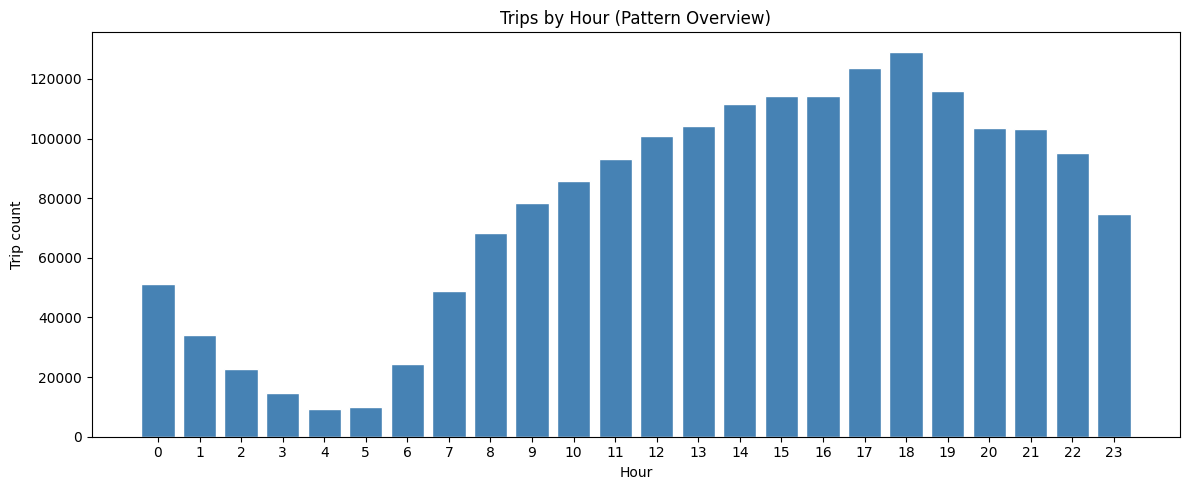

Busiest hour: 18:00 with 129,149 trips
Quietest hour: 4:00 with 9,429 trips
hour_of_the_day
0      51141
1      34229
2      22543
3      14707
4       9429
5      10019
6      24447
7      48960
8      68256
9      78260
10     85602
11     93001
12    100969
13    104059
14    111534
15    114243
16    114243
17    123518
18    129149
19    115889
20    103409
21    103118
22     95138
23     74815


In [9]:
# Find and show the hourly trends in taxi pickups

#   Getting hourly data for analysis
df['hour_of_the_day'] = df['tpep_pickup_datetime'].dt.hour

hourly_trips = df.groupby('hour_of_the_day').size()


# plotting a bar plot with the data
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(hourly_trips.index, hourly_trips.values, color='steelblue', edgecolor='white')

ax.set_xlabel('Hour')
ax.set_ylabel('Trip count')
ax.set_title('Trips by Hour (Pattern Overview)')

ax.set_xticks(range(24))

plt.tight_layout()
plt.show()


#   Getting max and lowest values for accurate values
peak_hour = hourly_trips.idxmax()
peak_trips = hourly_trips.max()
slowest_hour = hourly_trips.idxmin()
lowest_trips = hourly_trips.min()


# printing analysis
print(f'Busiest hour: {peak_hour}:00 with {peak_trips:,} trips')
print(f'Quietest hour: {slowest_hour}:00 with {lowest_trips:,} trips')

print(hourly_trips.to_string())  # to get the exact values if needed

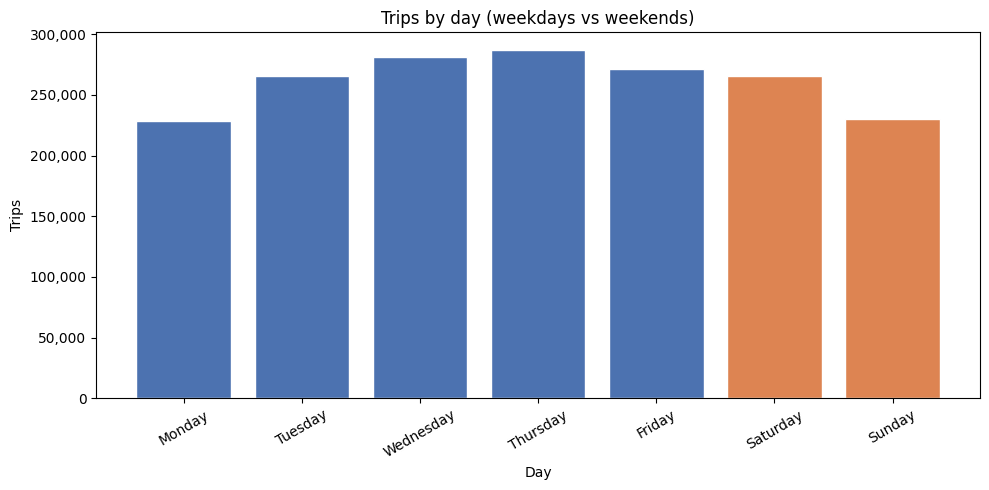

Trips per day:
day_name_variable
Monday       228868
Tuesday      265842
Wednesday    281460
Thursday     287157
Friday       271510
Saturday     265764
Sunday       230077


In [ ]:
# Find and show the daily trends in taxi pickups (days of the week)


#   Similiar to hourly analysis grouping day data
df['day_name_variable'] = df['tpep_pickup_datetime'].dt.day_name()

correct_day_list_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

total_trips_each_day = df.groupby('day_name_variable').size().reindex(correct_day_list_order)


# Plotting bar graph with weekend having different color
plot_window, plot_axes = plt.subplots(figsize=(10, 5))

bar_color_settings = ['#4c72b0'] * 5 + ['#dd8452'] * 2

plot_axes.bar(total_trips_each_day.index, total_trips_each_day.values,
              color=bar_color_settings, edgecolor='white')

plot_axes.set_xlabel('Day')
plot_axes.set_ylabel('Trips')
plot_axes.set_title('Trips by day (weekdays vs weekends)')

#   Formatting the values to avoid decimal values in plot
def format_y_axis_numbers(value_input, position_index):
    integer_converted_value = int(value_input)
    return f"{integer_converted_value:,}"

plot_axes.yaxis.set_major_formatter(plt.FuncFormatter(format_y_axis_numbers))

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Trips data extracted for analysis
day_results_string = total_trips_each_day.to_string()
print('Trips per day:')
print(day_results_string)


extracted_month_number
1     148420
2     140650
3     164208
4     158313
5     168927
6     158935
7     139657
8     135184
9     133883
10    166479
11    158313
12    157709


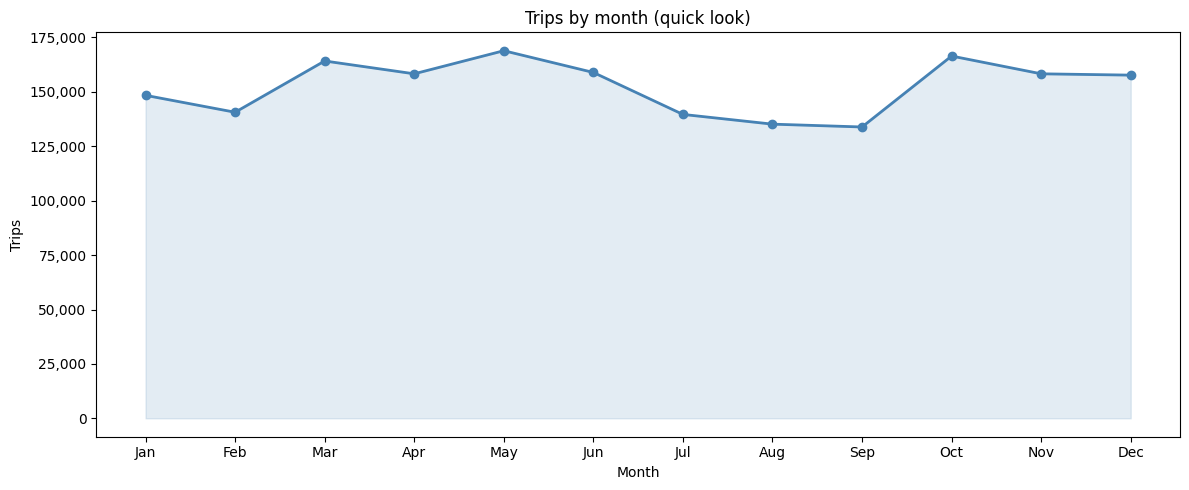


Busiest month: May (168,927)
Quietest month: Sep (133,883)


In [10]:
# Show the monthly trends in pickups (Similiar to previous analysis)

df['extracted_month_number'] = df['tpep_pickup_datetime'].dt.month

names_of_months_list = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                        'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

trips_sum_per_month = df.groupby('extracted_month_number').size()

monthly_data_text = trips_sum_per_month.to_string()
print(monthly_data_text)

main_graph_frame, main_graph_axis = plt.subplots(figsize=(12, 5))

main_graph_axis.plot(trips_sum_per_month.index, trips_sum_per_month.values,
                     marker='o', linewidth=2, color='steelblue')

main_graph_axis.fill_between(trips_sum_per_month.index, trips_sum_per_month.values,
                             alpha=0.15, color='steelblue')

main_graph_axis.set_xticks(range(1, 13))
main_graph_axis.set_xticklabels(names_of_months_list)

main_graph_axis.set_xlabel('Month')
main_graph_axis.set_ylabel('Trips')
main_graph_axis.set_title('Trips by month (quick look)')

def large_number_formatter(tick_value, tick_position):
    whole_number_value = int(tick_value)
    return f"{whole_number_value:,}"

main_graph_axis.yaxis.set_major_formatter(plt.FuncFormatter(large_number_formatter))

plt.tight_layout()
plt.show()

highest_month_index = trips_sum_per_month.idxmax()
lowest_month_index = trips_sum_per_month.idxmin()

highest_month_name = names_of_months_list[highest_month_index - 1]
lowest_month_name = names_of_months_list[lowest_month_index - 1]

peak_monthly_value = trips_sum_per_month.max()
bottom_monthly_value = trips_sum_per_month.min()

print(f"\nBusiest month: {highest_month_name} ({peak_monthly_value:,})")
print(f"Quietest month: {lowest_month_name} ({bottom_monthly_value:,})")

##### Financial Analysis

Take a look at the financial parameters like `fare_amount`, `tip_amount`, `total_amount`, and also `trip_distance`. Do these contain zero/negative values?

In [13]:
# Analyse the above parameters

# Making a list of columns to analyse
cols = ['fare_amount', 'tip_amount', 'total_amount', 'trip_distance']

df[cols].describe()


,fare_amount,tip_amount,total_amount,trip_distance
count,1830678.00,1830678.00,1830678.00,1830678.00
mean,19.73,3.57,28.86,3.45
std,18.15,4.07,22.79,4.53
min,0.00,0.00,0.00,0.00
25%,9.30,1.00,15.96,1.05
50%,13.50,2.86,21.00,1.79
75%,21.90,4.45,30.70,3.37
max,500.00,223.08,535.75,187.35


In [14]:
(df[cols] <= 0).sum() # Checking for negatives and zeros

,0
fare_amount,572
tip_amount,409641
total_amount,254
trip_distance,22331


In [15]:
df[(df[cols] <= 0).any(axis=1)].head() # checking in the df

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,trip_duration,hour_of_the_day,extracted_month_number
1,2,2023-09-01 00:24:50,2023-09-01 00:27:19,2,0.56,1,N,142,142,2,5.10,1.00,0.50,0.00,0.00,1.00,10.10,2.50,0.00,2.48,0,9
3,2,2023-09-01 00:42:13,2023-09-01 01:20:20,2,13.71,1,N,249,180,4,59.70,1.00,0.50,0.00,0.00,1.00,64.70,2.50,0.00,38.12,0,9
9,2,2023-09-01 00:04:45,2023-09-01 00:13:42,1,2.17,1,N,230,239,2,12.10,1.00,0.50,0.00,0.00,1.00,17.10,2.50,0.00,8.95,0,9
12,1,2023-09-01 00:09:36,2023-09-01 00:19:47,1,1.50,1,N,236,229,2,10.00,3.50,0.50,0.00,0.00,1.00,15.00,2.50,0.00,10.18,0,9
13,2,2023-09-01 00:15:18,2023-09-01 00:45:58,1,8.07,1,N,161,37,2,38.70,1.00,0.50,0.00,6.94,1.00,50.64,2.50,0.00,30.67,0,9


In [16]:
 #   percentage of zero values we solved neagtives in data cleaning
for col in cols:
    n = (df[col] == 0).sum()
    print(f'  {col:15s}: {n:>7,} zero rows ({n/len(df)*100:.2f}%)')

  fare_amount    :     572 zero rows (0.03%)
  tip_amount     : 409,641 zero rows (22.38%)
  total_amount   :     254 zero rows (0.01%)
  trip_distance  :  22,331 zero rows (1.22%)


Do you think it is beneficial to create a copy DataFrame leaving out the zero values from these?

**3.1.3** <font color = red>[2 marks]</font> <br>
Filter out the zero values from the above columns.

**Note:** The distance might be 0 in cases where pickup and drop is in the same zone. Do you think it is suitable to drop such cases of zero distance?

In [17]:
# Create a df with non zero entries for the selected parameters.

df_nz = df[
    (df['fare_amount']   > 0) &
    (df['total_amount']  > 0) &
    (df['trip_distance'] > 0)
].copy()


**3.1.4** <font color = red>[3 marks]</font> <br>
Analyse the monthly revenue (`total_amount`) trend

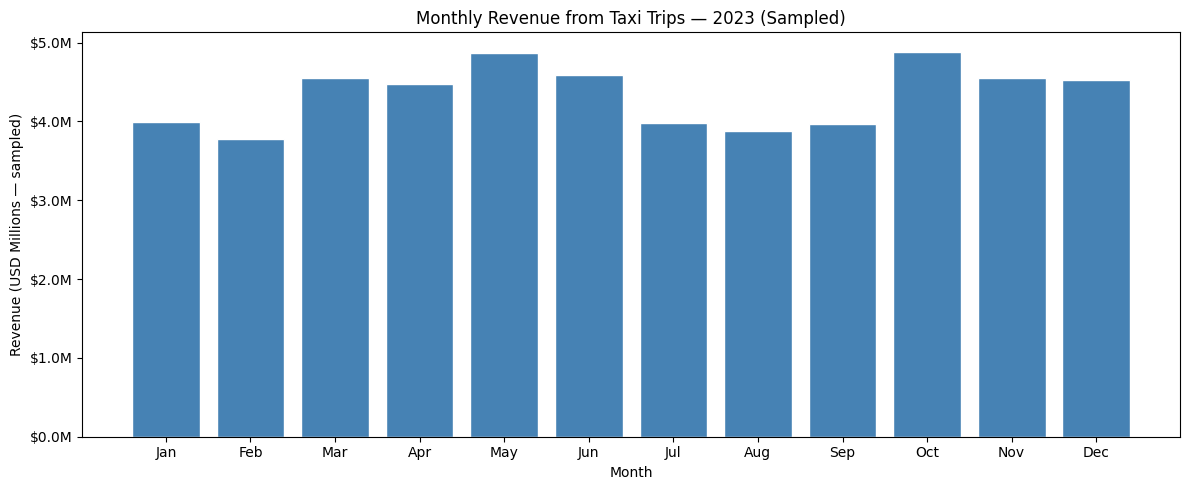

Monthly revenue (sampled $):
  Jan: $3,994,257.36
  Feb: $3,775,861.48
  Mar: $4,555,212.87
  Apr: $4,471,501.24
  May: $4,873,295.69
  Jun: $4,582,948.04
  Jul: $3,985,092.29
  Aug: $3,880,348.78
  Sep: $3,960,847.28
  Oct: $4,884,883.61
  Nov: $4,547,397.58
  Dec: $4,529,067.28

Peak month  : Oct
Lowest month: Feb


In [26]:
# Group data by month and analyse monthly revenue

monthly_rev = df_nz.groupby('extracted_month_number')['total_amount'].sum()

# using bar plot for monthly revenue visualization
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(monthly_rev.index, monthly_rev.values / 1e6,
       color='steelblue', edgecolor='white')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(names_of_months_list)
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (USD Millions — sampled)')
ax.set_title('Monthly Revenue from Taxi Trips — 2023 (Sampled)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:.1f}M'))
plt.tight_layout()
plt.show()

print('Monthly revenue (sampled $):')
for m, rev in monthly_rev.items():
    print(f'  {names_of_months_list[m-1]}: ${rev:>12,.2f}')
print(f'\nPeak month  : {names_of_months_list[monthly_rev.idxmax()-1]}')
print(f'Lowest month: {names_of_months_list[monthly_rev.idxmin()-1]}')

**3.1.5** <font color = red>[3 marks]</font> <br>
Show the proportion of each quarter of the year in the revenue

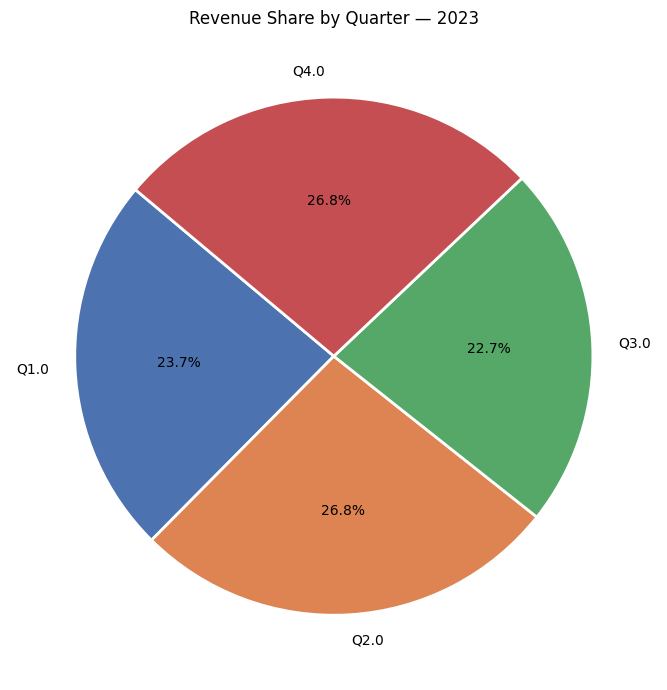

Quarterly revenue shares:
  Q1.0: 23.68%  ($12,325,331.71)
  Q2.0: 26.76%  ($13,927,744.97)
  Q3.0: 22.73%  ($11,826,288.35)
  Q4.0: 26.83%  ($13,961,348.47)


In [22]:
# Calculate proportion of each quarter
df_nz['pickup_quarter'] = df_nz['tpep_pickup_datetime'].dt.quarter
q_rev = df_nz.groupby('pickup_quarter')['total_amount'].sum()
q_pct = (q_rev / q_rev.sum() * 100).round(2)

# pie chart for Quarter visualization
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    q_rev,
    labels=[f'Q{q}' for q in q_rev.index],
    autopct='%1.1f%%',
    colors=['#4c72b0','#dd8452','#55a868','#c44e52'],
    startangle=140,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
ax.set_title('Revenue Share by Quarter — 2023')
plt.tight_layout()
plt.show()

print('Quarterly revenue shares:')
for q, pct in q_pct.items():
    print(f'  Q{q}: {pct}%  (${q_rev[q]:,.2f})')

**3.1.6** <font color = red>[3 marks]</font> <br>
Visualise the relationship between `trip_distance` and `fare_amount`. Also find the correlation value for these two.

**Hint:** You can leave out the trips with trip_distance = 0

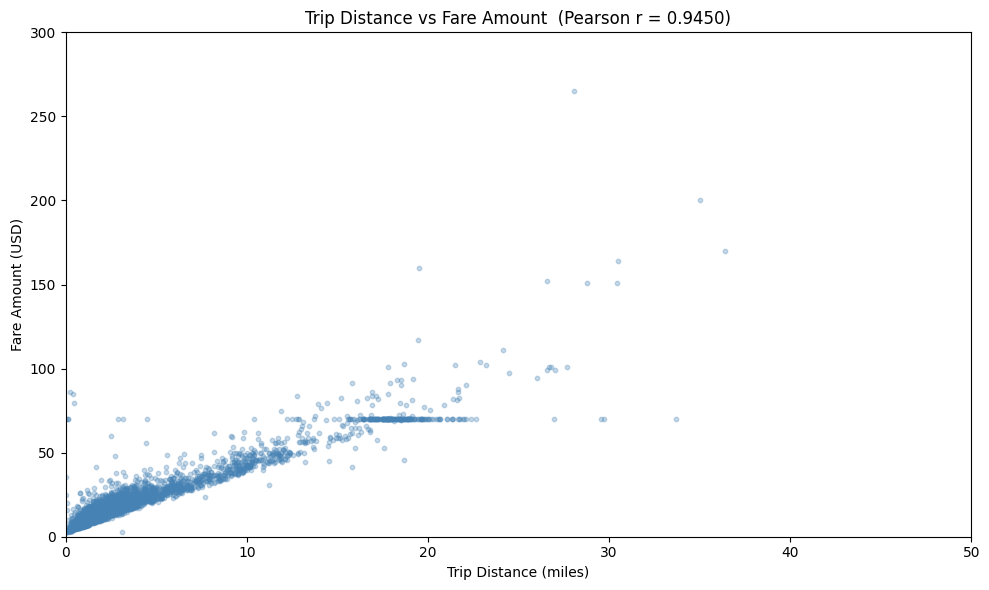

Correlation (trip_distance, fare_amount): 0.9450


In [28]:
# Show how trip fare is affected by distance

corr = df_nz['trip_distance'].corr(df['fare_amount'])
sample = df_nz.sample(5000, random_state=42)

# using scatterplot
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sample['trip_distance'], sample['fare_amount'],
           alpha=0.3, s=10, color='steelblue')
ax.set_xlabel('Trip Distance (miles)')
ax.set_ylabel('Fare Amount (USD)')
ax.set_title(f'Trip Distance vs Fare Amount  (Pearson r = {corr:.4f})')
ax.set_xlim(0, 50)
ax.set_ylim(0, 300)
plt.tight_layout()
plt.show()

print(f'Correlation (trip_distance, fare_amount): {corr:.4f}')


**3.1.7** <font color = red>[5 marks]</font> <br>
Find and visualise the correlation between:
1. `fare_amount` and trip duration (pickup time to dropoff time)
2. `fare_amount` and `passenger_count`
3. `tip_amount` and `trip_distance`

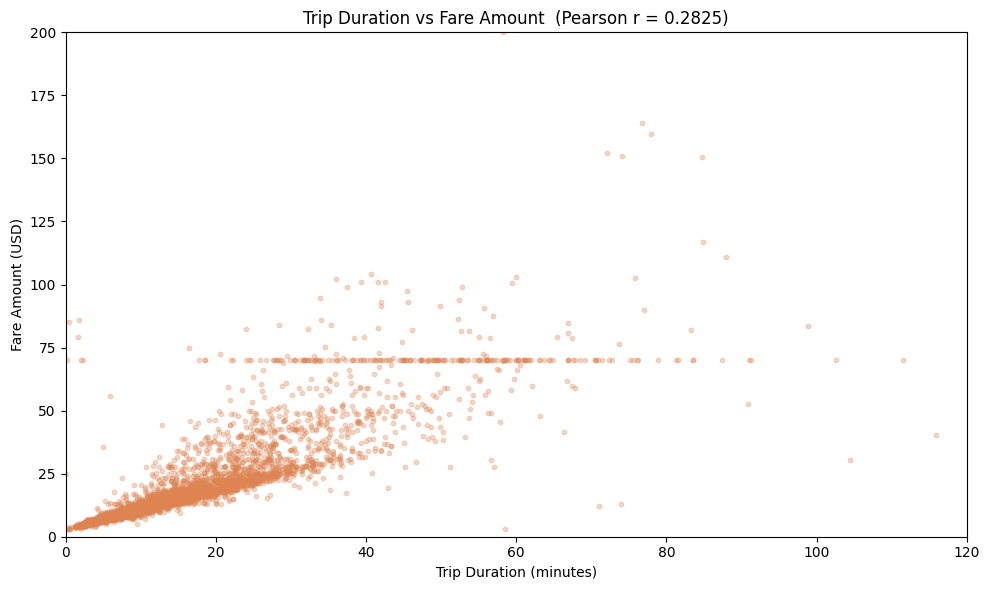

Correlation (trip_duration, fare_amount): 0.2825


In [29]:
# Show relationship between fare and trip duration

corr_dur = df_nz['trip_duration'].corr(df_nz['fare_amount'])
sample = df_nz.sample(5000, random_state=42)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sample['trip_duration'], sample['fare_amount'],
           alpha=0.3, s=10, color='#dd8452')
ax.set_xlabel('Trip Duration (minutes)')
ax.set_ylabel('Fare Amount (USD)')
ax.set_title(f'Trip Duration vs Fare Amount  (Pearson r = {corr_dur:.4f})')
ax.set_xlim(0, 120)
ax.set_ylim(0, 200)
plt.tight_layout()
plt.show()

print(f'Correlation (trip_duration, fare_amount): {corr_dur:.4f}')


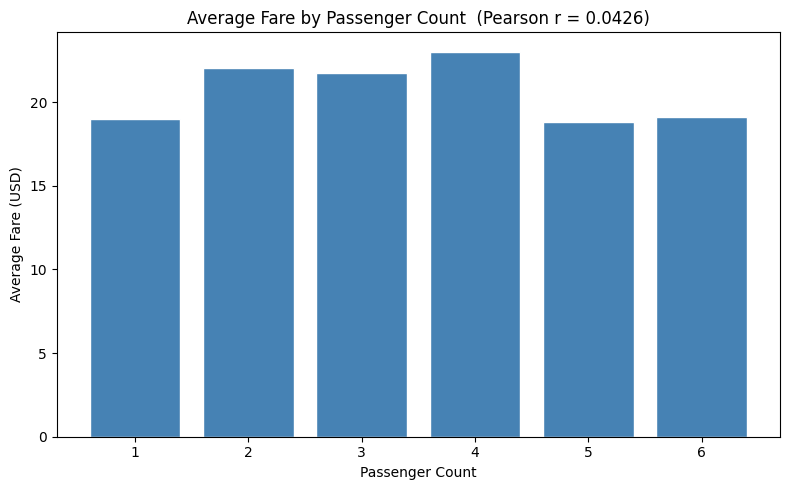

Correlation (passenger_count, fare_amount): 0.0426


In [30]:
# Show relationship between fare and number of passengers

corr_pax = df_nz['passenger_count'].corr(df_nz['fare_amount'])
avg_fare_pax = df_nz.groupby('passenger_count')['fare_amount'].mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(avg_fare_pax.index, avg_fare_pax.values, color='steelblue', edgecolor='white')
ax.set_xlabel('Passenger Count')
ax.set_ylabel('Average Fare (USD)')
ax.set_title(f'Average Fare by Passenger Count  (Pearson r = {corr_pax:.4f})')
plt.tight_layout()
plt.show()

print(f'Correlation (passenger_count, fare_amount): {corr_pax:.4f}')



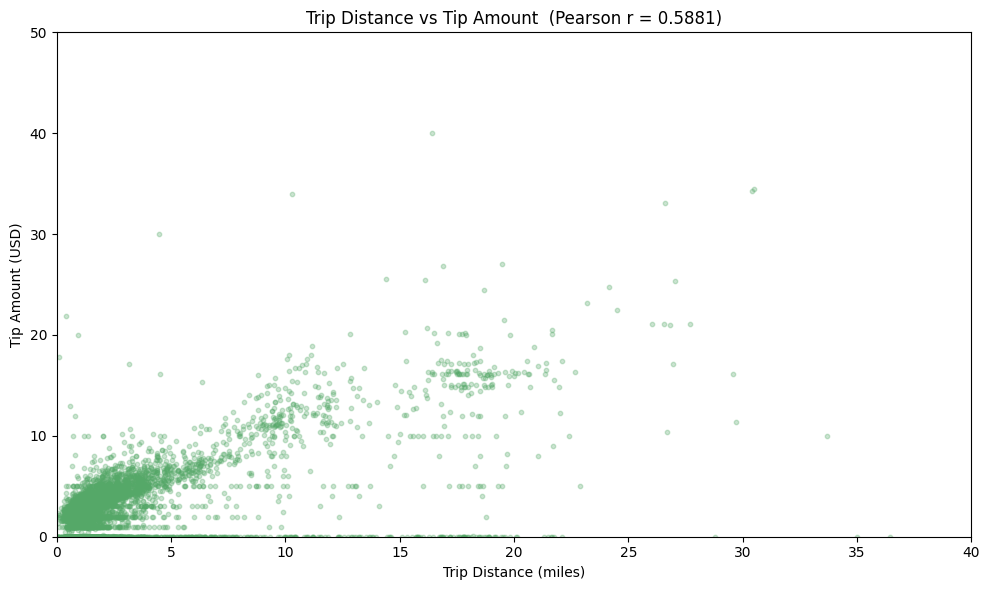

Correlation (trip_distance, tip_amount): 0.5881


In [31]:
# Show relationship between tip and trip distance

corr_tip = df_nz['tip_amount'].corr(df_nz['trip_distance'])
sample = df_nz.sample(5000, random_state=42)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sample['trip_distance'], sample['tip_amount'],
           alpha=0.3, s=10, color='#55a868')
ax.set_xlabel('Trip Distance (miles)')
ax.set_ylabel('Tip Amount (USD)')
ax.set_title(f'Trip Distance vs Tip Amount  (Pearson r = {corr_tip:.4f})')
ax.set_xlim(0, 40)
ax.set_ylim(0, 50)
plt.tight_layout()
plt.show()

print(f'Correlation (trip_distance, tip_amount): {corr_tip:.4f}')



**3.1.8** <font color = red>[3 marks]</font> <br>
Analyse the distribution of different payment types (`payment_type`)

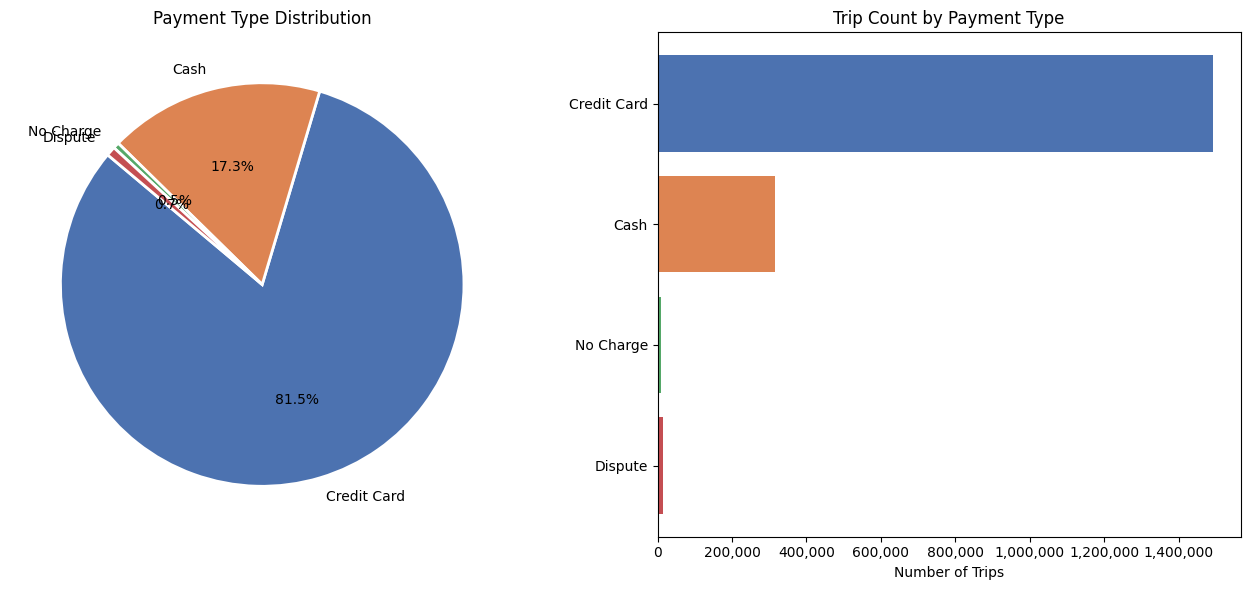

  Credit Card : 1,492,171 (81.5%)
  Cash        :   315,843 (17.3%)
  No Charge   :     8,995 (0.5%)
  Dispute     :    13,669 (0.7%)


In [32]:
# Analyse the distribution of different payment types (payment_type).

payment_labels = {1: 'Credit Card', 2: 'Cash', 3: 'No Charge', 4: 'Dispute'}
pt_counts = df['payment_type'].value_counts().sort_index()
pt_labels  = [payment_labels.get(k, str(k)) for k in pt_counts.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))

# pie chart to show percentage
ax1.pie(pt_counts, labels=pt_labels, autopct='%1.1f%%',
        colors=['#4c72b0','#dd8452','#55a868','#c44e52'],
        startangle=140, wedgeprops={'edgecolor':'white','linewidth':2})
ax1.set_title('Payment Type Distribution')
# bar plot in ax 2 for accurate visualization
ax2.barh(pt_labels[::-1], pt_counts.values[::-1],
         color=['#4c72b0','#dd8452','#55a868','#c44e52'][::-1])
ax2.set_xlabel('Number of Trips')
ax2.set_title('Trip Count by Payment Type')
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.show()

# printing individual values
for k, v in pt_counts.items():
    print(f'  {payment_labels.get(k,k):12s}: {v:>9,} ({v/len(df)*100:.1f}%)')


- 1= Credit card
- 2= Cash
- 3= No charge
- 4= Dispute



##### Geographical Analysis

For this, you have to use the *taxi_zones.shp* file from the *taxi_zones* folder.

There would be multiple files inside the folder (such as *.shx, .sbx, .sbn* etc). You do not need to import/read any of the files other than the shapefile, *taxi_zones.shp*.

Do not change any folder structure - all the files need to be present inside the folder for it to work.

The folder structure should look like this:
```
Taxi Zones
|- taxi_zones.shp.xml
|- taxi_zones.prj
|- taxi_zones.sbn
|- taxi_zones.shp
|- taxi_zones.dbf
|- taxi_zones.shx
|- taxi_zones.sbx

 ```

 You only need to read the `taxi_zones.shp` file. The *shp* file will utilise the other files by itself.

We will use the *GeoPandas* library for geopgraphical analysis
```
import geopandas as gpd
```

More about geopandas and shapefiles: [About](https://geopandas.org/en/stable/about.html)


Reading the shapefile is very similar to *Pandas*. Use `gpd.read_file()` function to load the data (*taxi_zones.shp*) as a GeoDataFrame. Documentation: [Reading and Writing Files](https://geopandas.org/en/stable/docs/user_guide/io.html)

In [ ]:
# !pip install geopandas

**3.1.9** <font color = red>[2 marks]</font> <br>
Load the shapefile and display it.

In [33]:
import geopandas as gpd


# Read the shapefile using geopandas
zones = gpd.read_file('/content/drive/MyDrive/NYC Assignment/taxi_zones/taxi_zones.shp')# read the .shp file using gpd
zones.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.12,0.00,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.43,0.00,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.08,0.00,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.04,0.00,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.09,0.00,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


Now, if you look at the DataFrame created, you will see columns like: `OBJECTID`,`Shape_Leng`, `Shape_Area`, `zone`, `LocationID`, `borough`, `geometry`.
<br><br>

Now, the `locationID` here is also what we are using to mark pickup and drop zones in the trip records.

The geometric parameters like shape length, shape area and geometry are used to plot the zones on a map.

This can be easily done using the `plot()` method.

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    263 non-null    int32   
 1   Shape_Leng  263 non-null    float64 
 2   Shape_Area  263 non-null    float64 
 3   zone        263 non-null    object  
 4   LocationID  263 non-null    int32   
 5   borough     263 non-null    object  
 6   geometry    263 non-null    geometry
dtypes: float64(2), geometry(1), int32(2), object(2)
memory usage: 12.5+ KB
None


<Axes: >

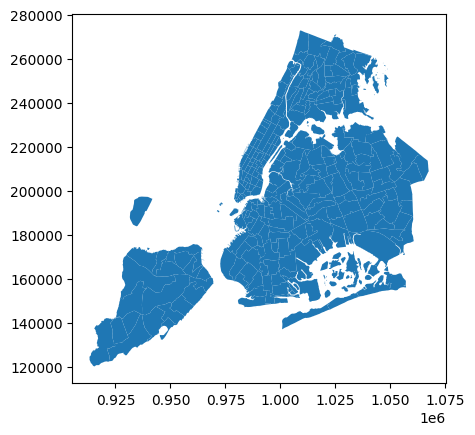

In [34]:
# printing the zone plot
print(zones.info())
zones.plot()

Now, you have to merge the trip records and zones data using the location IDs.



**3.1.10** <font color = red>[3 marks]</font> <br>
Merge the zones data into trip data using the `locationID` and `PULocationID` columns.

In [35]:
# Merge zones and trip records using locationID and PULocationID

df_geo = df.merge(
    zones[['LocationID', 'zone', 'borough', 'geometry']],
    left_on='PULocationID',
    right_on='LocationID',
    how='left'
)

df_geo[['PULocationID', 'zone', 'borough']].head()


,PULocationID,zone,borough
0,142,Lincoln Square East,Manhattan
1,132,JFK Airport,Queens
2,249,West Village,Manhattan
3,144,Little Italy/NoLiTa,Manhattan
4,79,East Village,Manhattan


**3.1.11** <font color = red>[3 marks]</font> <br>
Group data by location IDs to find the total number of trips per location ID

In [36]:
# Group data by location and calculate the number of trips

zone_trips = (
    df_geo.groupby('PULocationID')
    .size()
    .reset_index(name='trip_count')
    .rename(columns={'PULocationID': 'LocationID'})
)

print(f'Zones with at least one pickup: {len(zone_trips)}')
print(zone_trips.sort_values('trip_count', ascending=False).head(10).to_string(index=False))


Zones with at least one pickup: 257
 LocationID  trip_count
        132       96758
        237       86883
        161       85925
        236       77502
        162       65620
        138       64162
        186       63442
        230       61294
        142       60865
        170       54478


**3.1.12** <font color = red>[2 marks]</font> <br>
Now, use the grouped data to add number of trips to the GeoDataFrame.

We will use this to plot a map of zones showing total trips per zone.

In [37]:
# Merge trip counts back to the zones GeoDataFrame

zones_with_trips = zones.merge(zone_trips, on='LocationID', how='left')
zones_with_trips['trip_count'] = zones_with_trips['trip_count'].fillna(0)

print(f'Total zones in shapefile : {len(zones_with_trips)}')
print(f'Zones with > 0 pickups   : {(zones_with_trips["trip_count"] > 0).sum()}')



Total zones in shapefile : 263
Zones with > 0 pickups   : 255


The next step is creating a color map (choropleth map) showing zones by the number of trips taken.

Again, you can use the `zones.plot()` method for this. [Plot Method GPD](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html#geopandas.GeoDataFrame.plot)

But first, you need to define the figure and axis for the plot.

`fig, ax = plt.subplots(1, 1, figsize = (12, 10))`

This function creates a figure (fig) and a single subplot (ax)

---

After setting up the figure and axis, we can proceed to plot the GeoDataFrame on this axis. This is done in the next step where we use the plot method of the GeoDataFrame.

You can define the following parameters in the `zones.plot()` method:
```
column = '',
ax = ax,
legend = True,
legend_kwds = {'label': "label", 'orientation': "<horizontal/vertical>"}
```

To display the plot, use `plt.show()`.

**3.1.13** <font color = red>[3 marks]</font> <br>
Plot a color-coded map showing zone-wise trips

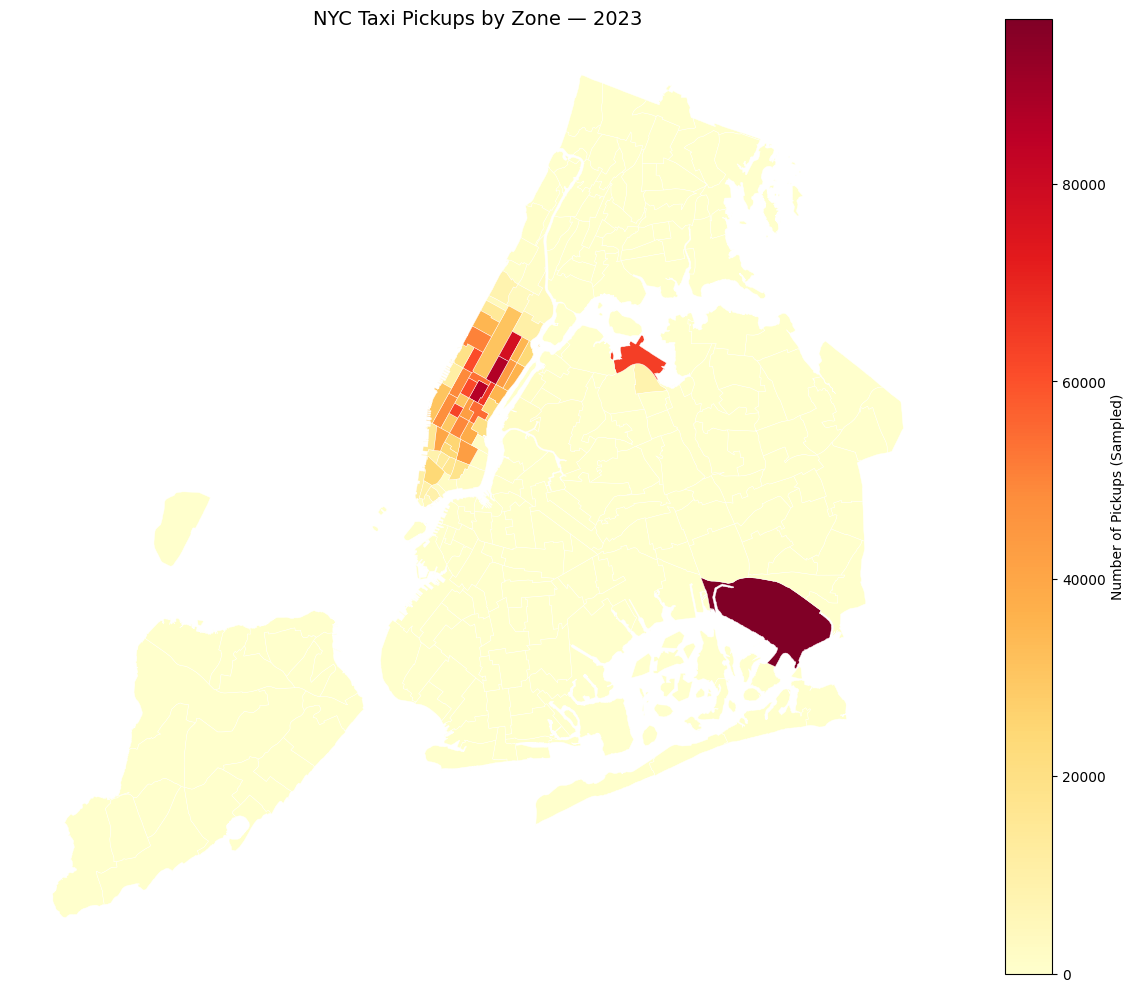

In [38]:
# Define figure and axis

fig, ax = plt.subplots(1, 1, figsize=(12, 10))

# Plot the map and display it

zones_with_trips.plot(
    column='trip_count',
    ax=ax,
    legend=True,
    legend_kwds={'label': 'Number of Pickups (Sampled)', 'orientation': 'vertical'},
    cmap='YlOrRd',
    edgecolor='white',
    linewidth=0.3
)
ax.set_title('NYC Taxi Pickups by Zone — 2023', fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.show()


In [40]:
# can you try displaying the zones DF sorted by the number of trips?

top_zones = (
    zones_with_trips[['zone', 'borough', 'trip_count']]
    .sort_values('trip_count', ascending=False)
    .head(15)
    .reset_index(drop=True)
)
top_zones.index += 1
print(top_zones.to_string())


                            zone    borough  trip_count
1                    JFK Airport     Queens    96758.00
2          Upper East Side South  Manhattan    86883.00
3                 Midtown Center  Manhattan    85925.00
4          Upper East Side North  Manhattan    77502.00
5                   Midtown East  Manhattan    65620.00
6              LaGuardia Airport     Queens    64162.00
7   Penn Station/Madison Sq West  Manhattan    63442.00
8      Times Sq/Theatre District  Manhattan    61294.00
9            Lincoln Square East  Manhattan    60865.00
10                   Murray Hill  Manhattan    54478.00
11                 Midtown North  Manhattan    53745.00
12         Upper West Side South  Manhattan    50337.00
13                      Union Sq  Manhattan    49369.00
14                  Clinton East  Manhattan    48784.00
15                  East Chelsea  Manhattan    47778.00


Here we have completed the temporal, financial and geographical analysis on the trip records.

**Compile your findings from general analysis below:**

You can consider the following points:

* Busiest hours, days and months
* Trends in revenue collected
* Trends in quarterly revenue
* How fare depends on trip distance, trip duration and passenger counts
* How tip amount depends on trip distance
* Busiest zones


#### **3.2** Detailed EDA: Insights and Strategies
<font color = red>[50 marks]</font> <br>

Having performed basic analyses for finding trends and patterns, we will now move on to some detailed analysis focussed on operational efficiency, pricing strategies, and customer experience.

##### Operational Efficiency

Analyze variations by time of day and location to identify bottlenecks or inefficiencies in routes

**3.2.1** <font color = red>[3 marks]</font> <br>
Identify slow routes by calculating the average time taken by cabs to get from one zone to another at different hours of the day.

Speed on a route *X* for hour *Y* = (*distance of the route X / average trip duration for hour Y*)

In [ ]:
# Find routes which have the slowest speeds at different times of the day

df_routes = df[(df['trip_distance'] > 0) & (df['trip_duration'] >= 5)].copy()

# getting speed
route_speed = (
    df_routes.groupby(['PULocationID', 'DOLocationID', 'pickup_hour'])
    .agg(
        avg_distance_mi =('trip_distance', 'mean'),
        avg_duration_min=('trip_duration', 'mean'),
        trip_count      =('trip_distance', 'count')
    )
    .reset_index()
)

# for findding avg speed
route_speed = route_speed[route_speed['trip_count'] >= 10].copy()
route_speed['avg_speed_mph'] = (route_speed['avg_distance_mi'] / (route_speed['avg_duration_min'] / 60)).round(2)
# finding slowest based on avg speed as base
slowest = route_speed.nsmallest(10, 'avg_speed_mph')
print('Top 10 slowest route-hour combinations (min 10 trips):')
print(slowest[['PULocationID','DOLocationID','pickup_hour','avg_speed_mph','avg_duration_min','trip_count']].to_string(index=False))


Top 10 slowest route-hour combinations (min 10 trips):
 PULocationID  DOLocationID  pickup_hour  avg_speed_mph  avg_duration_min  trip_count
          148            45           23           0.36            150.98          10
          114           113           11           0.39            135.96          11
          236           263           22           0.44            123.80          12
          246            68            2           0.44            147.34          10
          125           158           21           0.49            136.70          11
          113           113           13           0.51             86.47          18
          107           137            0           0.52            109.12          14
          113             4           23           0.53            128.20          12
          113           234            1           0.54            135.82          11
          148           148            3           0.54             96.47          16

How does identifying high-traffic, high-demand routes help us?

**3.2.2** <font color = red>[3 marks]</font> <br>
Calculate the number of trips at each hour of the day and visualise them. Find the busiest hour and show the number of trips for that hour.

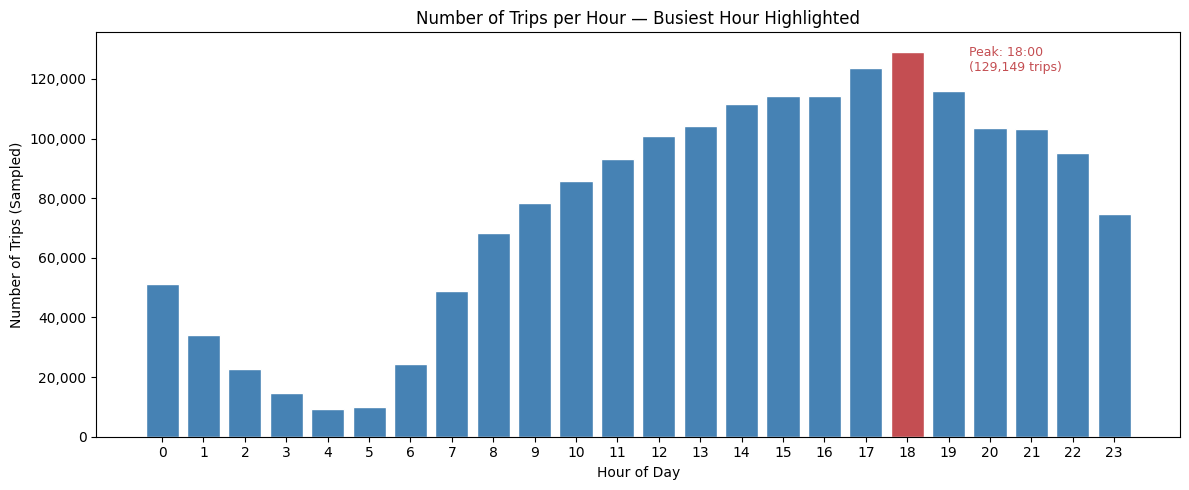

Busiest hour: 18:00 with 129,149 sampled trips


In [41]:
# Visualise the number of trips per hour and find the busiest hour

# busiest hour found
busiest_hour = hourly_trips.idxmax()

# red colour for busiest hour easy visualization
fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#c44e52' if h == busiest_hour else 'steelblue'
          for h in hourly_trips.index]
ax.bar(hourly_trips.index, hourly_trips.values, color=colors, edgecolor='white')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Number of Trips (Sampled)')
ax.set_title('Number of Trips per Hour — Busiest Hour Highlighted')
ax.set_xticks(range(0, 24))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.annotate(
    f'Peak: {busiest_hour}:00\n({hourly_trips[busiest_hour]:,} trips)',
    xy=(busiest_hour, hourly_trips[busiest_hour]),
    xytext=(busiest_hour + 1.5, hourly_trips[busiest_hour] * 0.95),
    fontsize=9, color='#c44e52'
)
plt.tight_layout()
plt.show()

print(f'Busiest hour: {busiest_hour}:00 with {hourly_trips[busiest_hour]:,} sampled trips')


Remember, we took a fraction of trips. To find the actual number, you have to scale the number up by the sampling ratio.

**3.2.3** <font color = red>[2 mark]</font> <br>
Find the actual number of trips in the five busiest hours

In [42]:
# Scale up the number of trips

# Fill in the value of your sampling fraction and use that to scale up the numbers
sample_fraction = 0.05
scale_factor    = int(1 / sample_fraction)  # factor = 20

scaled_hourly = (hourly_trips * scale_factor).astype(int)
top5 = scaled_hourly.nlargest(5)

print(f'Scale factor applied : x{scale_factor}')
print('\nEstimated actual trips for the 5 busiest hours across the year:')
for hour, count in top5.items():
    print(f'  {hour:02d}:00  →  ~{count:>12,} trips')



Scale factor applied : x20

Estimated actual trips for the 5 busiest hours across the year:
  18:00  →  ~   2,582,980 trips
  17:00  →  ~   2,470,360 trips
  19:00  →  ~   2,317,780 trips
  15:00  →  ~   2,284,860 trips
  16:00  →  ~   2,284,860 trips


**3.2.4** <font color = red>[3 marks]</font> <br>
Compare hourly traffic pattern on weekdays. Also compare for weekend.

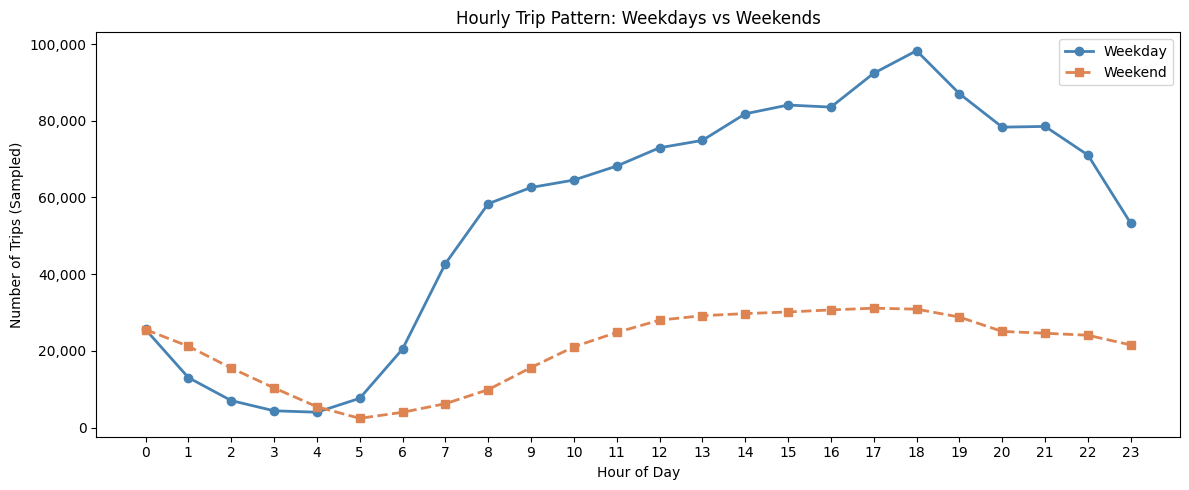

Weekday peak: 18:00 (98,272 trips)
Weekend peak: 17:00 (31,125 trips)


In [45]:
# Compare traffic trends for the week days and weekends
# getting weekday  andd weekend dates separate
df['pickup_dow'] = df['tpep_pickup_datetime'].dt.dayofweek # Monday=0, Sunday=6
df['is_weekend'] = df['pickup_dow'].isin([5, 6])

# hourly calculation for weekday and weekend
hourly_wkday = df[~df['is_weekend']].groupby('hour_of_the_day').size()
hourly_wkend = df[ df['is_weekend']].groupby('hour_of_the_day').size()

# plotting in line graph
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hourly_wkday.index, hourly_wkday.values,
        marker='o', label='Weekday', linewidth=2, color='steelblue')
ax.plot(hourly_wkend.index, hourly_wkend.values,
        marker='s', label='Weekend', linewidth=2,
        color='#dd8452', linestyle='--')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Number of Trips (Sampled)')
ax.set_title('Hourly Trip Pattern: Weekdays vs Weekends')
ax.set_xticks(range(0, 24))
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

# results
print(f'Weekday peak: {hourly_wkday.idxmax()}:00 ({hourly_wkday.max():,} trips)')
print(f'Weekend peak: {hourly_wkend.idxmax()}:00 ({hourly_wkend.max():,} trips)')

What can you infer from the above patterns? How will finding busy and quiet hours for each day help us?

**3.2.5** <font color = red>[3 marks]</font> <br>
Identify top 10 zones with high hourly pickups. Do the same for hourly dropoffs. Show pickup and dropoff trends in these zones.

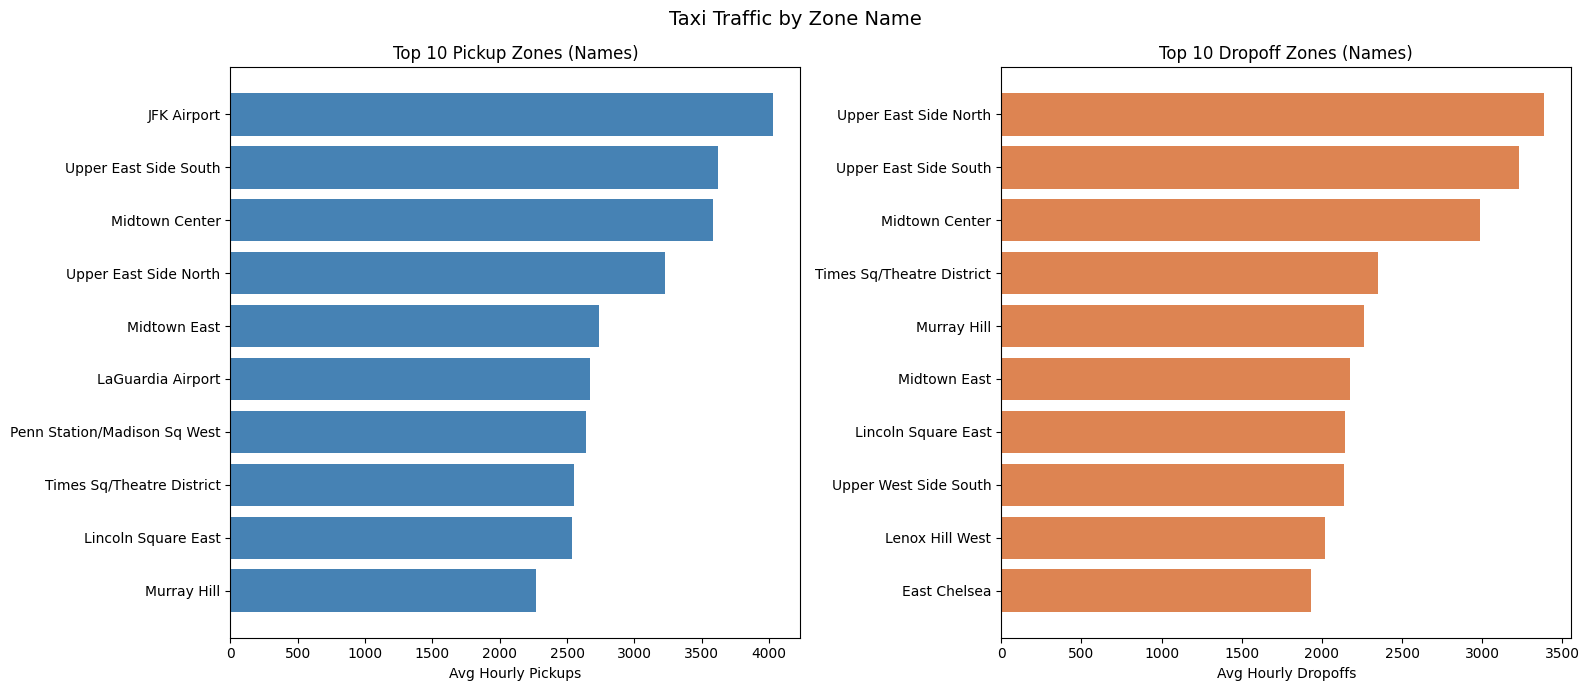

Top 10 Pickup Locations:
                        zone  pickup_avg
                 JFK Airport     4031.58
       Upper East Side South     3620.12
              Midtown Center     3580.21
       Upper East Side North     3229.25
                Midtown East     2734.17
           LaGuardia Airport     2673.42
Penn Station/Madison Sq West     2643.42
   Times Sq/Theatre District     2553.92
         Lincoln Square East     2536.04
                 Murray Hill     2269.92

Top 10 Dropoff Locations:
                     zone  dropoff_avg
    Upper East Side North      3386.04
    Upper East Side South      3231.38
           Midtown Center      2985.25
Times Sq/Theatre District      2349.92
              Murray Hill      2262.92
             Midtown East      2176.96
      Lincoln Square East      2145.54
    Upper West Side South      2135.58
          Lenox Hill West      2018.58
             East Chelsea      1931.29


In [50]:
# Find top 10 pickup and dropoff zones
# getting hourly pickup and dropoff based on ids
pickup_counts_by_id = df.groupby('PULocationID').size() / 24
dropoff_counts_by_id = df.groupby('DOLocationID').size() / 24

pickup_stats_frame = pickup_counts_by_id.reset_index()
pickup_stats_frame.columns = ['LocationID', 'pickup_avg']

dropoff_stats_frame = dropoff_counts_by_id.reset_index()
dropoff_stats_frame.columns = ['LocationID', 'dropoff_avg']

zones['LocationID'] = zones['LocationID'].astype(int)
pickup_stats_frame['LocationID'] = pickup_stats_frame['LocationID'].astype(int)
dropoff_stats_frame['LocationID'] = dropoff_stats_frame['LocationID'].astype(int)

# Converting Zone nos to zone names by merging with zones df
merged_pickups = pickup_stats_frame.merge(zones[['LocationID', 'zone']], on='LocationID')
merged_dropoffs = dropoff_stats_frame.merge(zones[['LocationID', 'zone']], on='LocationID')
# getting top 10 largest
top_ten_pickup_names = merged_pickups.nlargest(10, 'pickup_avg')
top_ten_dropoff_names = merged_dropoffs.nlargest(10, 'dropoff_avg')
# comparison plotting
comparison_figure, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(16, 7))

left_axis.barh(top_ten_pickup_names['zone'][::-1],
               top_ten_pickup_names['pickup_avg'][::-1], color='steelblue')
left_axis.set_xlabel('Avg Hourly Pickups')
left_axis.set_title('Top 10 Pickup Zones (Names)')

right_axis.barh(top_ten_dropoff_names['zone'][::-1],
                top_ten_dropoff_names['dropoff_avg'][::-1], color='#dd8452')
right_axis.set_xlabel('Avg Hourly Dropoffs')
right_axis.set_title('Top 10 Dropoff Zones (Names)')

plt.suptitle('Taxi Traffic by Zone Name', fontsize=14)
plt.tight_layout()
plt.show()

print('Top 10 Pickup Locations:')
print(top_ten_pickup_names[['zone', 'pickup_avg']].to_string(index=False))

print('\nTop 10 Dropoff Locations:')
print(top_ten_dropoff_names[['zone', 'dropoff_avg']].to_string(index=False))

**3.2.6** <font color = red>[3 marks]</font> <br>
Find the ratio of pickups and dropoffs in each zone. Display the 10 highest (pickup/drop) and 10 lowest (pickup/drop) ratios.

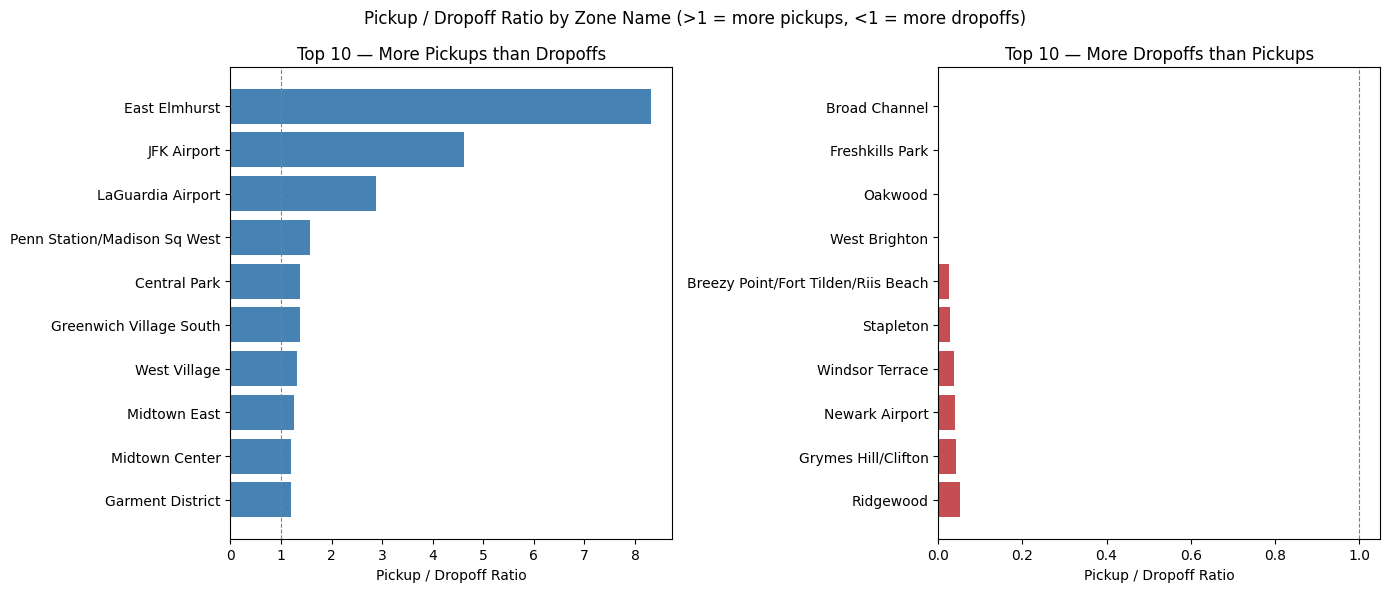

Highest ratios (zones generating more outbound trips):
                        zone  pickups  dropoffs  pickup_to_dropoff_ratio
               East Elmhurst  8349.00   1004.00                     8.32
                 JFK Airport 96758.00  20968.00                     4.62
           LaGuardia Airport 64162.00  22247.00                     2.88
Penn Station/Madison Sq West 63442.00  40116.00                     1.58
                Central Park 30748.00  22367.00                     1.38
     Greenwich Village South 24102.00  17539.00                     1.37
                West Village 40392.00  30466.00                     1.33
                Midtown East 65620.00  52247.00                     1.26
              Midtown Center 85925.00  71646.00                     1.20
            Garment District 30198.00  25344.00                     1.19

Lowest ratios (zones absorbing more inbound trips):
                               zone  pickups  dropoffs  pickup_to_dropoff_ratio
         

In [52]:
# Find the top 10 and bottom 10 pickup/dropoff ratios
# Similiar to previous ones but with ratios
pickup_totals_per_zone = df.groupby('PULocationID').size().rename('pickups')
dropoff_totals_per_zone = df.groupby('DOLocationID').size().rename('dropoffs')

# concatting with zones for names instead of ids
combined_zone_data_frame = pd.concat([pickup_totals_per_zone, dropoff_totals_per_zone], axis=1).fillna(0)
combined_zone_data_frame = combined_zone_data_frame[combined_zone_data_frame['dropoffs'] > 0].copy()

# creating a ratio column
combined_zone_data_frame['pickup_to_dropoff_ratio'] = (
    combined_zone_data_frame['pickups'] / combined_zone_data_frame['dropoffs']
).round(3)

combined_zone_data_frame = combined_zone_data_frame.reset_index()
combined_zone_data_frame.columns = ['LocationID', 'pickups', 'dropoffs', 'pickup_to_dropoff_ratio']

zones['LocationID'] = zones['LocationID'].astype(int)
combined_zone_data_frame['LocationID'] = combined_zone_data_frame['LocationID'].astype(int)

zone_data_with_names = combined_zone_data_frame.merge(zones[['LocationID', 'zone']], on='LocationID')

# list of high and low ratios
high_ratio_zones_list = zone_data_with_names.nlargest(10, 'pickup_to_dropoff_ratio')
low_ratio_zones_list = zone_data_with_names.nsmallest(10, 'pickup_to_dropoff_ratio')

# comparison plot
ratio_comparison_fig, (left_ratio_plot, right_ratio_plot) = plt.subplots(1, 2, figsize=(14, 6))

left_ratio_plot.barh(high_ratio_zones_list['zone'][::-1],
                     high_ratio_zones_list['pickup_to_dropoff_ratio'][::-1], color='steelblue')
left_ratio_plot.set_xlabel('Pickup / Dropoff Ratio')
left_ratio_plot.set_title('Top 10 — More Pickups than Dropoffs')
left_ratio_plot.axvline(1, linestyle='--', color='grey', linewidth=0.8)

right_ratio_plot.barh(low_ratio_zones_list['zone'][::-1],
                      low_ratio_zones_list['pickup_to_dropoff_ratio'][::-1], color='#c44e52')
right_ratio_plot.set_xlabel('Pickup / Dropoff Ratio')
right_ratio_plot.set_title('Top 10 — More Dropoffs than Pickups')
right_ratio_plot.axvline(1, linestyle='--', color='grey', linewidth=0.8)

plt.suptitle('Pickup / Dropoff Ratio by Zone Name (>1 = more pickups, <1 = more dropoffs)', fontsize=12)
plt.tight_layout()
plt.show()

# results for viewing
print('Highest ratios (zones generating more outbound trips):')
print(high_ratio_zones_list[['zone', 'pickups', 'dropoffs', 'pickup_to_dropoff_ratio']].to_string(index=False))

print('\nLowest ratios (zones absorbing more inbound trips):')
print(low_ratio_zones_list[['zone', 'pickups', 'dropoffs', 'pickup_to_dropoff_ratio']].to_string(index=False))

**3.2.7** <font color = red>[3 marks]</font> <br>
Identify zones with high pickup and dropoff traffic during night hours (11PM to 5AM)

Night-hour trips: 216,883 (11.8% of total)


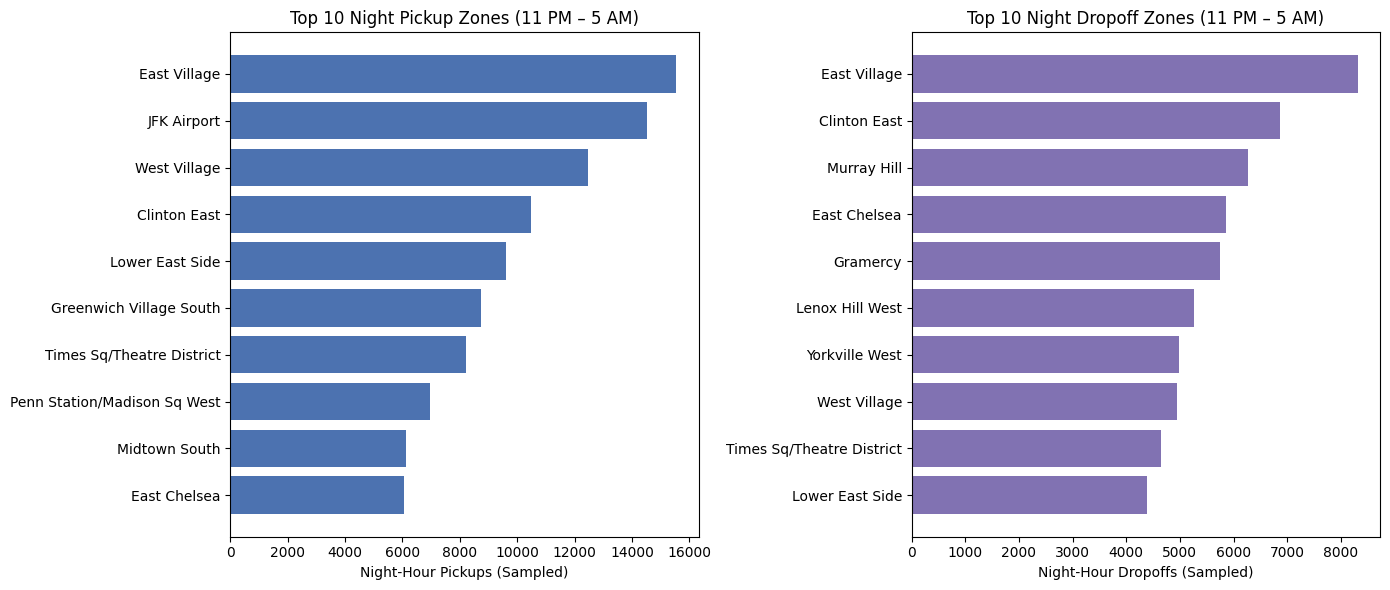

Top night pickup zones:
                        zone  pickup_count
                East Village         15548
                 JFK Airport         14539
                West Village         12465
                Clinton East         10462
             Lower East Side          9619
     Greenwich Village South          8744
   Times Sq/Theatre District          8204
Penn Station/Madison Sq West          6962
               Midtown South          6138
                East Chelsea          6047

Top night dropoff zones:
                     zone  dropoff_count
             East Village           8314
             Clinton East           6874
              Murray Hill           6264
             East Chelsea           5858
                 Gramercy           5756
          Lenox Hill West           5271
           Yorkville West           4976
             West Village           4944
Times Sq/Theatre District           4641
          Lower East Side           4381


In [55]:
# During night hours (11pm to 5am) find the top 10 pickup and dropoff zones
# Note that the top zones should be of night hours and not the overall top zones

# extracting night data
night_time_data_subset = df[df['hour_of_the_day'].isin([23, 0, 1, 2, 3, 4, 5])].copy()
# counting night trips
total_night_trips_count = len(night_time_data_subset)
total_data_count = len(df)
percentage_of_night_trips = (total_night_trips_count / total_data_count) * 100

# outputing night trip amount and percentage
print(f'Night-hour trips: {total_night_trips_count:,} ({percentage_of_night_trips:.1f}% of total)')

# Getting zone names for easier visualizatiobn
night_pickup_counts = night_time_data_subset.groupby('PULocationID').size().reset_index()
night_pickup_counts.columns = ['LocationID', 'pickup_count']

night_dropoff_counts = night_time_data_subset.groupby('DOLocationID').size().reset_index()
night_dropoff_counts.columns = ['LocationID', 'dropoff_count']

zones['LocationID'] = zones['LocationID'].astype(int)
night_pickup_counts['LocationID'] = night_pickup_counts['LocationID'].astype(int)
night_dropoff_counts['LocationID'] = night_dropoff_counts['LocationID'].astype(int)

night_pickups_with_names = night_pickup_counts.merge(zones[['LocationID', 'zone']], on='LocationID')
night_dropoffs_with_names = night_dropoff_counts.merge(zones[['LocationID', 'zone']], on='LocationID')

# getting top 10 pickups and dropoffs
top_ten_night_pickups = night_pickups_with_names.nlargest(10, 'pickup_count')
top_ten_night_dropoffs = night_dropoffs_with_names.nlargest(10, 'dropoff_count')

# plotting Comparison btwn pickups and dropoffs
night_plot_window, (night_left_ax, night_right_ax) = plt.subplots(1, 2, figsize=(14, 6))

night_left_ax.barh(top_ten_night_pickups['zone'][::-1],
                   top_ten_night_pickups['pickup_count'][::-1], color='#4c72b0')
night_left_ax.set_xlabel('Night-Hour Pickups (Sampled)')
night_left_ax.set_title('Top 10 Night Pickup Zones (11 PM – 5 AM)')

night_right_ax.barh(top_ten_night_dropoffs['zone'][::-1],
                    top_ten_night_dropoffs['dropoff_count'][::-1], color='#8172b2')
night_right_ax.set_xlabel('Night-Hour Dropoffs (Sampled)')
night_right_ax.set_title('Top 10 Night Dropoff Zones (11 PM – 5 AM)')

plt.tight_layout()
plt.show()

print('Top night pickup zones:')
print(top_ten_night_pickups[['zone', 'pickup_count']].to_string(index=False))

print('\nTop night dropoff zones:')
print(top_ten_night_dropoffs[['zone', 'dropoff_count']].to_string(index=False))

Now, let us find the revenue share for the night time hours and the day time hours. After this, we will move to deciding a pricing strategy.

**3.2.8** <font color = red>[2 marks]</font> <br>
Find the revenue share for nighttime and daytime hours.

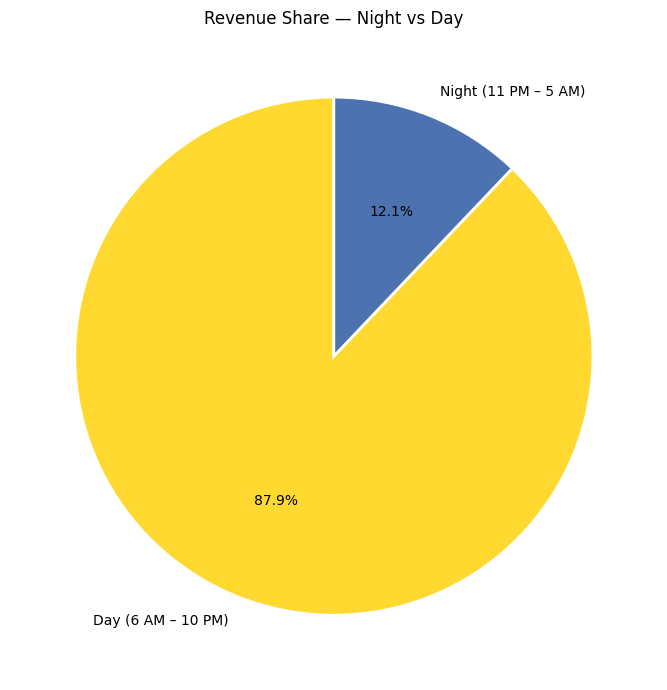

Revenue split:
  Day (6 AM – 10 PM): $46,437,062.27 (87.91%)
  Night (11 PM – 5 AM): $6,389,246.21 (12.09%)


In [57]:
# Filter for night hours (11 PM to 5 AM)

df['time_period'] = np.where(
    df['hour_of_the_day'].isin([23, 0, 1, 2, 3, 4, 5]),
    'Night (11 PM – 5 AM)',
    'Day (6 AM – 10 PM)'
)

rev_split = df.groupby('time_period')['total_amount'].sum()
rev_pct   = (rev_split / rev_split.sum() * 100).round(2)

# pie chart btwn day and night revenue
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    rev_split,
    labels=rev_split.index,
    autopct='%1.1f%%',
    colors=['#ffd92f', '#4c72b0'],
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
ax.set_title('Revenue Share — Night vs Day')
plt.tight_layout()
plt.show()

print('Revenue split:')
for period, rev in rev_split.items():
    print(f'  {period}: ${rev:>12,.2f} ({rev_pct[period]}%)')

##### Pricing Strategy

**3.2.9** <font color = red>[2 marks]</font> <br>
For the different passenger counts, find the average fare per mile per passenger.

For instance, suppose the average fare per mile for trips with 3 passengers is 3 USD/mile, then the fare per mile per passenger will be 1 USD/mile.

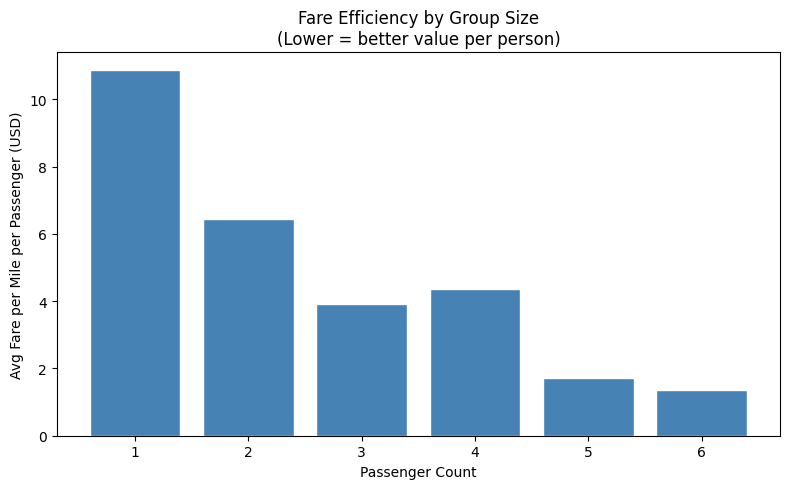

Average fare per mile per passenger:
  1 passenger(s): $10.86/mile/person
  2 passenger(s): $6.43/mile/person
  3 passenger(s): $3.91/mile/person
  4 passenger(s): $4.36/mile/person
  5 passenger(s): $1.71/mile/person
  6 passenger(s): $1.35/mile/person


In [58]:
# Analyse the fare per mile per passenger for different passenger counts

df = df[(df['fare_amount'] > 0) & (df['trip_distance'] > 0)].copy()
df['fare_per_mile'] = df['fare_amount'] / df['trip_distance']

# Fare per mile per passenger = fare / distance / passenger_count
fpm_pax = df.groupby('passenger_count').apply(
    lambda g: (g['fare_amount'] / g['trip_distance'] / g['passenger_count']).mean()
).round(2)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(fpm_pax.index, fpm_pax.values, color='steelblue', edgecolor='white')
ax.set_xlabel('Passenger Count')
ax.set_ylabel('Avg Fare per Mile per Passenger (USD)')
ax.set_title('Fare Efficiency by Group Size\n(Lower = better value per person)')
plt.tight_layout()
plt.show()

print('Average fare per mile per passenger:')
for pax, val in fpm_pax.items():
    print(f'  {pax} passenger(s): ${val:.2f}/mile/person')


**3.2.10** <font color = red>[3 marks]</font> <br>
Find the average fare per mile by hours of the day and by days of the week

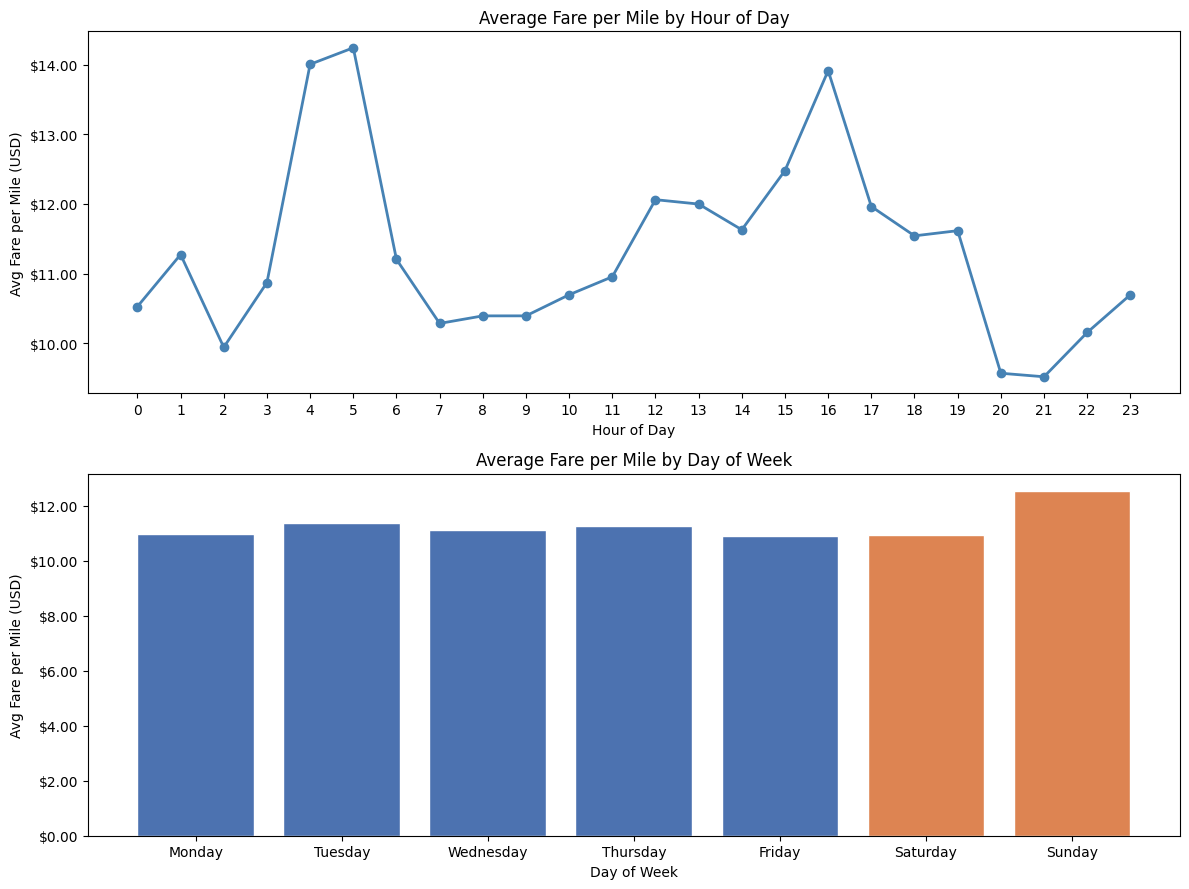

Highest fare/mile hour : 5:00  ($14.24/mile)
Highest fare/mile day  : Sunday  ($12.53/mile)


In [64]:
# Compare the average fare per mile for different days and for different times of the day

day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

fpm_hour = df.groupby('hour_of_the_day')['fare_per_mile'].mean()
fpm_day  = df.groupby(df['tpep_pickup_datetime'].dt.day_name())['fare_per_mile'].mean().reindex(day_order)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))

ax1.plot(fpm_hour.index, fpm_hour.values,
         marker='o', linewidth=2, color='steelblue')
ax1.set_xlabel('Hour of Day')
ax1.set_ylabel('Avg Fare per Mile (USD)')
ax1.set_title('Average Fare per Mile by Hour of Day')
ax1.set_xticks(range(0, 24))
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:.2f}'))

ax2.bar(fpm_day.index, fpm_day.values,
        color=['#4c72b0']*5 + ['#dd8452']*2, edgecolor='white')
ax2.set_xlabel('Day of Week')
ax2.set_ylabel('Avg Fare per Mile (USD)')
ax2.set_title('Average Fare per Mile by Day of Week')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:.2f}'))

plt.tight_layout()
plt.show()

print(f'Highest fare/mile hour : {fpm_hour.idxmax()}:00  (${fpm_hour.max():.2f}/mile)')
print(f'Highest fare/mile day  : {fpm_day.idxmax()}  (${fpm_day.max():.2f}/mile)')


**3.2.11** <font color = red>[3 marks]</font> <br>
Analyse the average fare per mile for the different vendors for different hours of the day

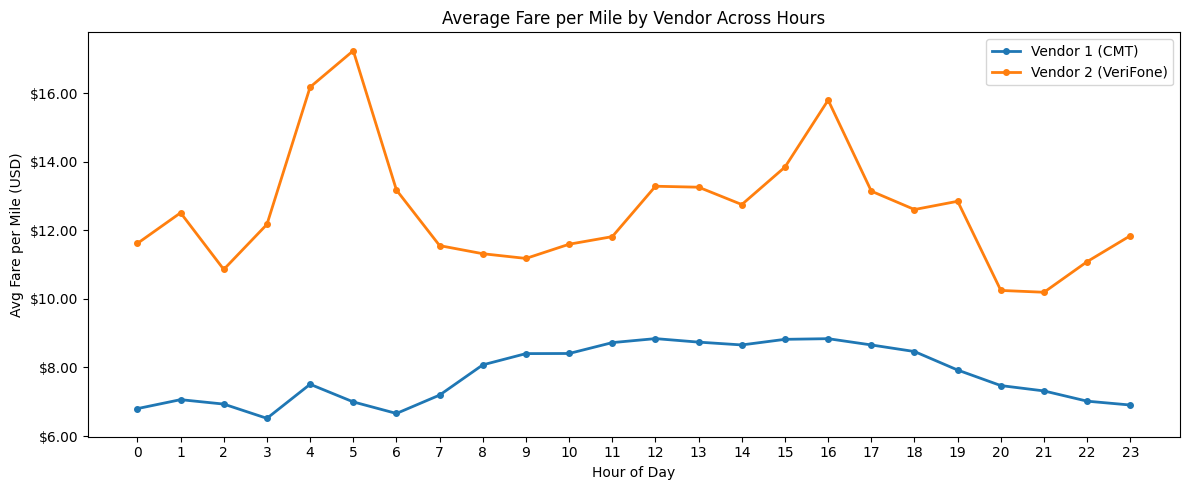

Overall average fare per mile by vendor:
  Vendor 1 (CMT): $8.13/mile
  Vendor 2 (VeriFone): $12.40/mile


In [66]:
# Compare fare per mile for different vendors

vendor_labels = {1: 'Vendor 1 (CMT)', 2: 'Vendor 2 (VeriFone)'}

vendor_fpm = (
    df.groupby(['VendorID', 'hour_of_the_day'])['fare_per_mile']
    .mean()
    .unstack('VendorID')
)

fig, ax = plt.subplots(figsize=(12, 5))
for v_id, label in vendor_labels.items():
    if v_id in vendor_fpm.columns:
        ax.plot(vendor_fpm.index, vendor_fpm[v_id],
                marker='o', markersize=4, label=label, linewidth=2)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Avg Fare per Mile (USD)')
ax.set_title('Average Fare per Mile by Vendor Across Hours')
ax.set_xticks(range(0, 24))
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:.2f}'))
plt.tight_layout()
plt.show()

overall = df.groupby('VendorID')['fare_per_mile'].mean()
print('Overall average fare per mile by vendor:')
for v, fpm in overall.items():
    print(f'  {vendor_labels[v]}: ${fpm:.2f}/mile')


**3.2.12** <font color = red>[5 marks]</font> <br>
Compare the fare rates of the different vendors in a tiered fashion. Analyse the average fare per mile for distances upto 2 miles. Analyse the fare per mile for distances from 2 to 5 miles. And then for distances more than 5 miles.


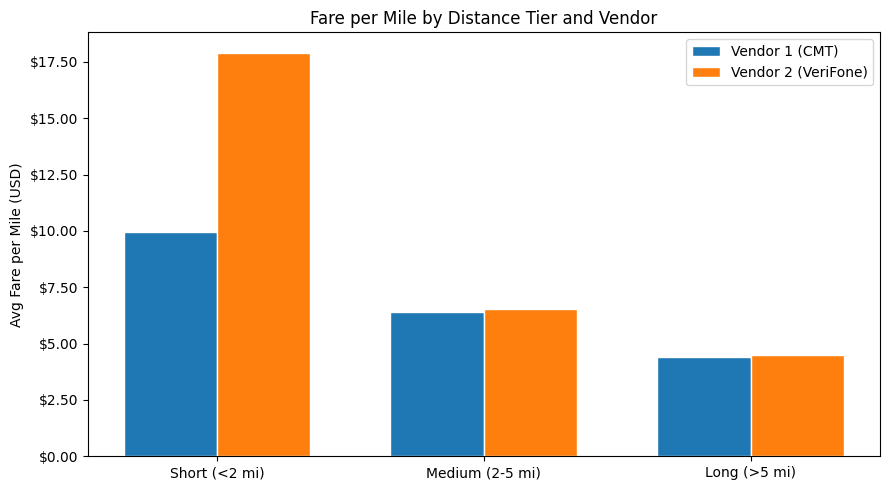

Avg fare per mile by distance tier and vendor:
VendorID         Vendor 1 (CMT)  Vendor 2 (VeriFone)
dist_tier                                           
Short (<2 mi)              9.93                17.91
Medium (2-5 mi)            6.38                 6.55
Long (>5 mi)               4.43                 4.50


In [67]:
# Defining distance tiers

vendor_labels = {1: 'Vendor 1 (CMT)', 2: 'Vendor 2 (VeriFone)'}

df['dist_tier'] = pd.cut(
    df['trip_distance'],
    bins=[0, 2, 5, np.inf],
    labels=['Short (<2 mi)', 'Medium (2-5 mi)', 'Long (>5 mi)']
)

tier_vendor = (
    df.groupby(['dist_tier', 'VendorID'], observed=True)['fare_per_mile']
    .mean()
    .unstack('VendorID')
    .rename(columns=vendor_labels)
)

x     = np.arange(len(tier_vendor))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
for j, col in enumerate(tier_vendor.columns):
    ax.bar(x + j * width, tier_vendor[col], width,
           label=col, edgecolor='white')
ax.set_xticks(x + width / 2)
ax.set_xticklabels(tier_vendor.index)
ax.set_ylabel('Avg Fare per Mile (USD)')
ax.set_title('Fare per Mile by Distance Tier and Vendor')
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:.2f}'))
plt.tight_layout()
plt.show()

print('Avg fare per mile by distance tier and vendor:')
print(tier_vendor.round(2).to_string())

##### Customer Experience and Other Factors

**3.2.13** <font color = red>[5 marks]</font> <br>
Analyse average tip percentages based on trip distances, passenger counts and time of pickup. What factors lead to low tip percentages?

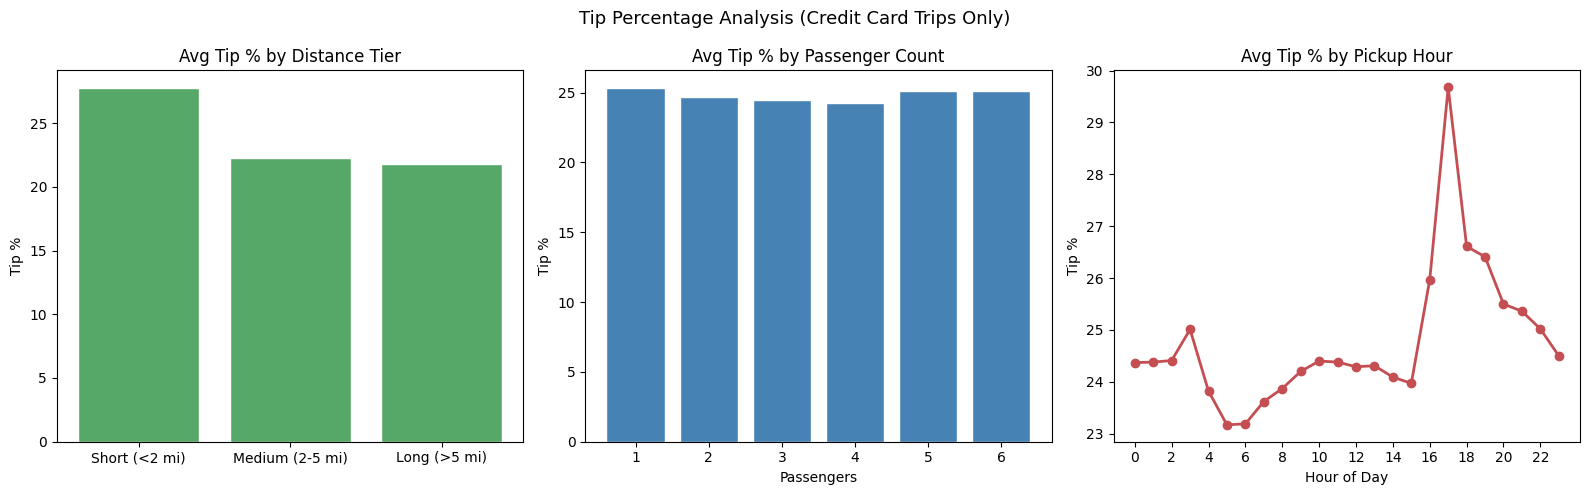

Avg tip % by distance tier:
dist_tier
Short (<2 mi)     27.75
Medium (2-5 mi)   22.23
Long (>5 mi)      21.77

Avg tip % by passenger count:
passenger_count
1   25.33
2   24.69
3   24.45
4   24.26
5   25.09
6   25.15

Lowest tip hour : 5:00 (23.17%)
Highest tip hour: 17:00 (29.68%)


In [69]:
#  Analyze tip percentages based on distances, passenger counts and pickup times

card_df = df[df['payment_type'] == 1].copy()
card_df['tip_pct'] = (card_df['tip_amount'] / card_df['fare_amount'] * 100).round(2)

card_df['dist_tier'] = pd.cut(
    card_df['trip_distance'],
    bins=[0, 2, 5, np.inf],
    labels=['Short (<2 mi)', 'Medium (2-5 mi)', 'Long (>5 mi)']
)
tip_by_dist = card_df.groupby('dist_tier', observed=True)['tip_pct'].mean().round(2)
tip_by_pax  = card_df.groupby('passenger_count')['tip_pct'].mean().round(2)
tip_by_hour = card_df.groupby('hour_of_the_day')['tip_pct'].mean().round(2)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].bar(tip_by_dist.index, tip_by_dist.values, color='#55a868', edgecolor='white')
axes[0].set_title('Avg Tip % by Distance Tier')
axes[0].set_ylabel('Tip %')

axes[1].bar(tip_by_pax.index, tip_by_pax.values, color='steelblue', edgecolor='white')
axes[1].set_title('Avg Tip % by Passenger Count')
axes[1].set_ylabel('Tip %')
axes[1].set_xlabel('Passengers')

axes[2].plot(tip_by_hour.index, tip_by_hour.values,
             marker='o', linewidth=2, color='#c44e52')
axes[2].set_title('Avg Tip % by Pickup Hour')
axes[2].set_ylabel('Tip %')
axes[2].set_xlabel('Hour of Day')
axes[2].set_xticks(range(0, 24, 2))

plt.suptitle('Tip Percentage Analysis (Credit Card Trips Only)', fontsize=13)
plt.tight_layout()
plt.show()

print('Avg tip % by distance tier:')
print(tip_by_dist.to_string())
print('\nAvg tip % by passenger count:')
print(tip_by_pax.to_string())
print(f'\nLowest tip hour : {tip_by_hour.idxmin()}:00 ({tip_by_hour.min():.2f}%)')
print(f'Highest tip hour: {tip_by_hour.idxmax()}:00 ({tip_by_hour.max():.2f}%)')


Additional analysis [optional]: Let's try comparing cases of low tips with cases of high tips to find out if we find a clear aspect that drives up the tipping behaviours

In [70]:
# Compare trips with tip percentage < 10% to trips with tip percentage > 25%

low_tip  = card_df[card_df['tip_pct'] < 10]
high_tip = card_df[card_df['tip_pct'] > 25]

compare_cols = ['trip_distance', 'trip_duration', 'fare_amount', 'passenger_count']
compare = pd.DataFrame({
    'Low Tip (<10%)' : low_tip[compare_cols].mean(),
    'High Tip (>25%)': high_tip[compare_cols].mean()
}).round(2)

print(f'Low tip trips (<10%):  {len(low_tip):,}')
print(f'High tip trips (>25%): {len(high_tip):,}')
print('\nAverage characteristics comparison:')
print(compare.to_string())


Low tip trips (<10%):  142,272
High tip trips (>25%): 813,339

Average characteristics comparison:
                 Low Tip (<10%)  High Tip (>25%)
trip_distance              4.86             2.30
trip_duration             24.93            12.74
fare_amount               25.72            14.41
passenger_count            1.38             1.36


**3.2.14** <font color = red>[3 marks]</font> <br>
Analyse the variation of passenger count across hours and days of the week.

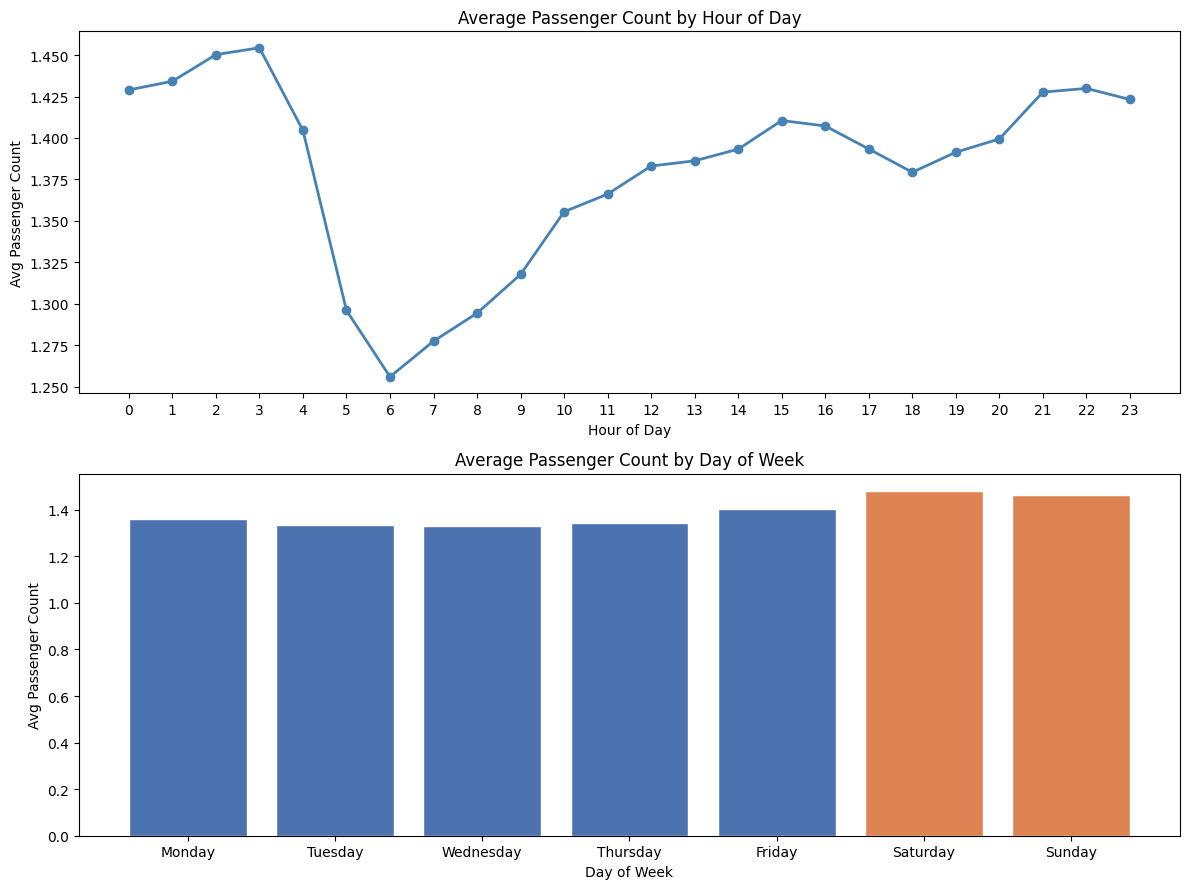

Hour with most passengers on avg: 3:00 (1.45)
Day with most passengers on avg : Saturday (1.48)


In [73]:
# See how passenger count varies across hours and days

day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

avg_pax_hour = df.groupby('hour_of_the_day')['passenger_count'].mean()
avg_pax_day  = df.groupby(df['tpep_pickup_datetime'].dt.day_name())['passenger_count'].mean().reindex(day_order)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))

ax1.plot(avg_pax_hour.index, avg_pax_hour.values,
         marker='o', linewidth=2, color='steelblue')
ax1.set_xlabel('Hour of Day')
ax1.set_ylabel('Avg Passenger Count')
ax1.set_title('Average Passenger Count by Hour of Day')
ax1.set_xticks(range(0, 24))

ax2.bar(avg_pax_day.index, avg_pax_day.values,
        color=['#4c72b0']*5 + ['#dd8452']*2, edgecolor='white')
ax2.set_xlabel('Day of Week')
ax2.set_ylabel('Avg Passenger Count')
ax2.set_title('Average Passenger Count by Day of Week')

plt.tight_layout()
plt.show()

print(f'Hour with most passengers on avg: {avg_pax_hour.idxmax()}:00 ({avg_pax_hour.max():.2f})')
print(f'Day with most passengers on avg : {avg_pax_day.idxmax()} ({avg_pax_day.max():.2f})')

**3.2.15** <font color = red>[2 marks]</font> <br>
Analyse the variation of passenger counts across zones

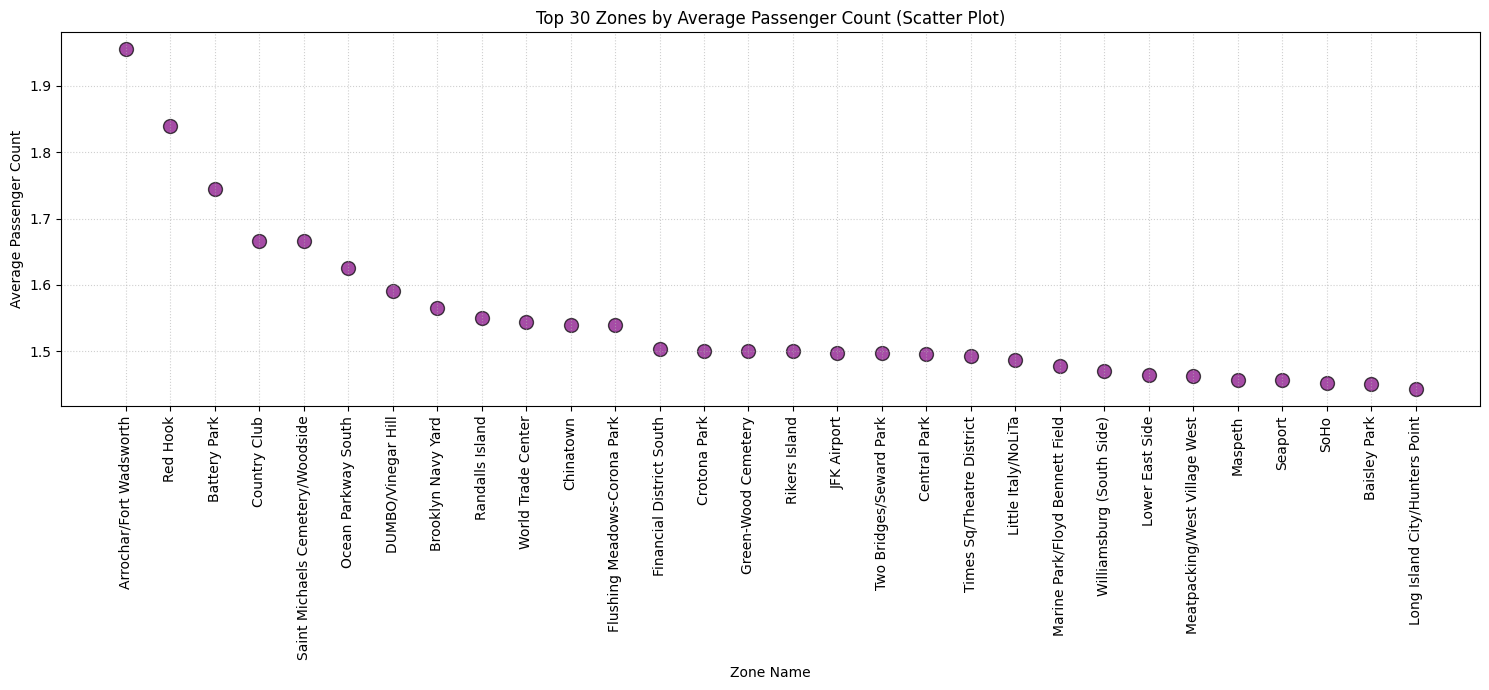

Top 30 zones by average passenger count:
                            zone  avg_pax_count
         Arrochar/Fort Wadsworth           1.95
                        Red Hook           1.84
                    Battery Park           1.74
                    Country Club           1.67
Saint Michaels Cemetery/Woodside           1.67
             Ocean Parkway South           1.62
              DUMBO/Vinegar Hill           1.59
              Brooklyn Navy Yard           1.57
                 Randalls Island           1.55
              World Trade Center           1.54
                       Chinatown           1.54
    Flushing Meadows-Corona Park           1.54
        Financial District South           1.50
                    Crotona Park           1.50
             Green-Wood Cemetery           1.50
                   Rikers Island           1.50
                     JFK Airport           1.50
         Two Bridges/Seward Park           1.50
                    Central Park           1.50

In [76]:
# How does passenger count vary across zones
# avg passenger count for each zone
average_passengers_per_zone_data = (
    df.groupby('PULocationID')['passenger_count']
    .mean()
    .reset_index()
)

average_passengers_per_zone_data.columns = ['LocationID', 'avg_pax_count']
# merging with zones to get zone names and not numbers
zones['LocationID'] = zones['LocationID'].astype(int)
average_passengers_per_zone_data['LocationID'] = average_passengers_per_zone_data['LocationID'].astype(int)

full_pax_zone_table = average_passengers_per_zone_data.merge(zones[['LocationID', 'zone']], on='LocationID')

# only taking top 30 values for analysis
top_thirty_pax_zones = full_pax_zone_table.nlargest(30, 'avg_pax_count')

# plotting top 30 values
plt.figure(figsize=(15, 7))

plt.scatter(top_thirty_pax_zones['zone'],
            top_thirty_pax_zones['avg_pax_count'],
            color='purple',
            alpha=0.7,
            s=100,
            edgecolor='black')

plt.xticks(rotation=90)

plt.xlabel('Zone Name')
plt.ylabel('Average Passenger Count')
plt.title('Top 30 Zones by Average Passenger Count (Scatter Plot)')

plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print('Top 30 zones by average passenger count:')
print(top_thirty_pax_zones[['zone', 'avg_pax_count']].to_string(index=False))

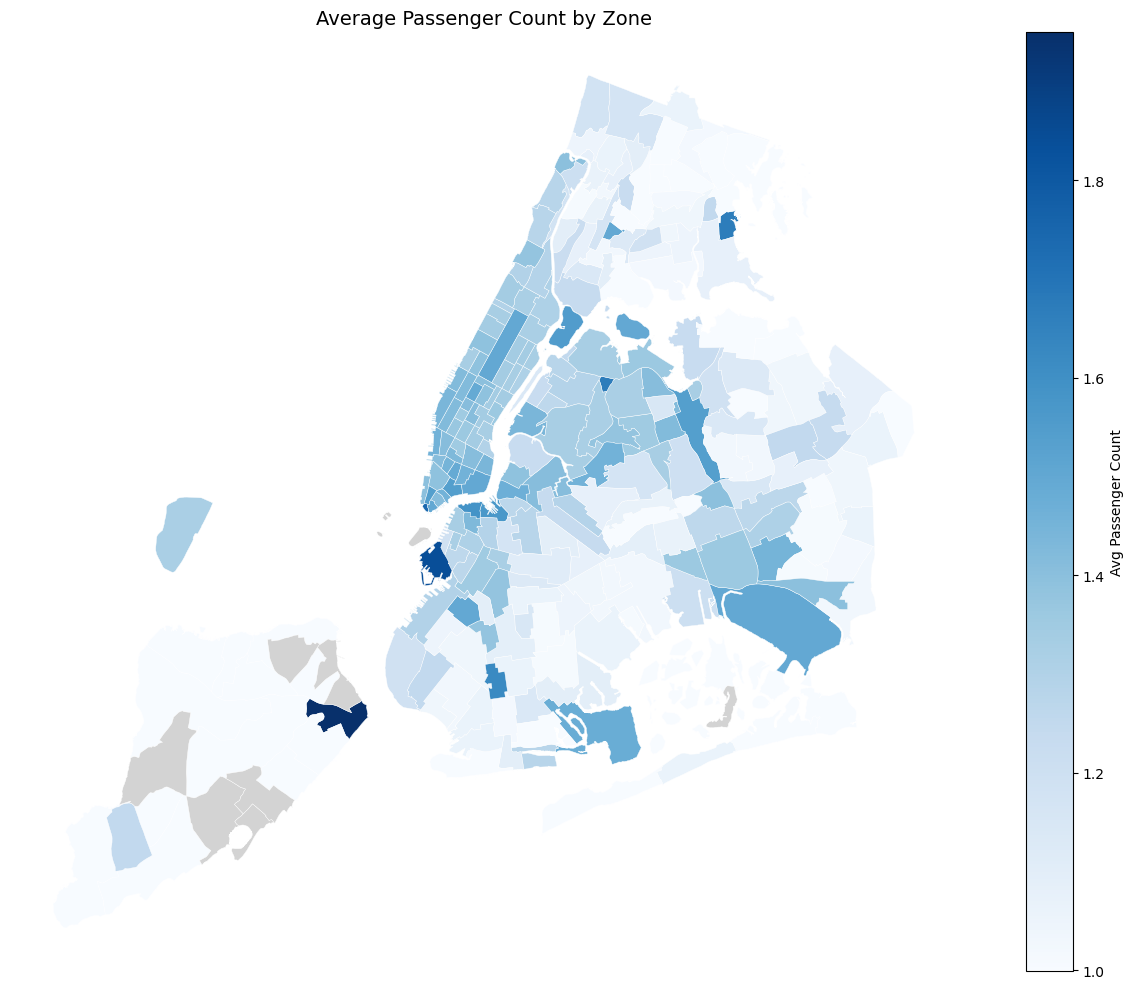

In [77]:
# For a more detailed analysis, we can use the zones_with_trips GeoDataFrame
# Create a new column for the average passenger count in each zone.

zone_pax_df = zone_pax.reset_index()
zone_pax_df.columns = ['LocationID', 'avg_passengers']

zones_with_trips = zones_with_trips.merge(zone_pax_df, on='LocationID', how='left')

# heatmap on zone plot
fig, ax = plt.subplots(1, 1, figsize=(14, 10))
zones_with_trips.plot(
    column='avg_passengers',
    ax=ax,
    legend=True,
    legend_kwds={'label': 'Avg Passenger Count', 'orientation': 'vertical'},
    cmap='Blues',
    edgecolor='white',
    linewidth=0.3,
    missing_kwds={'color': 'lightgrey'}
)
ax.set_title('Average Passenger Count by Zone', fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.show()


Find out how often surcharges/extra charges are applied to understand their prevalance

**3.2.16** <font color = red>[5 marks]</font> <br>
Analyse the pickup/dropoff zones or times when extra charges are applied more frequently

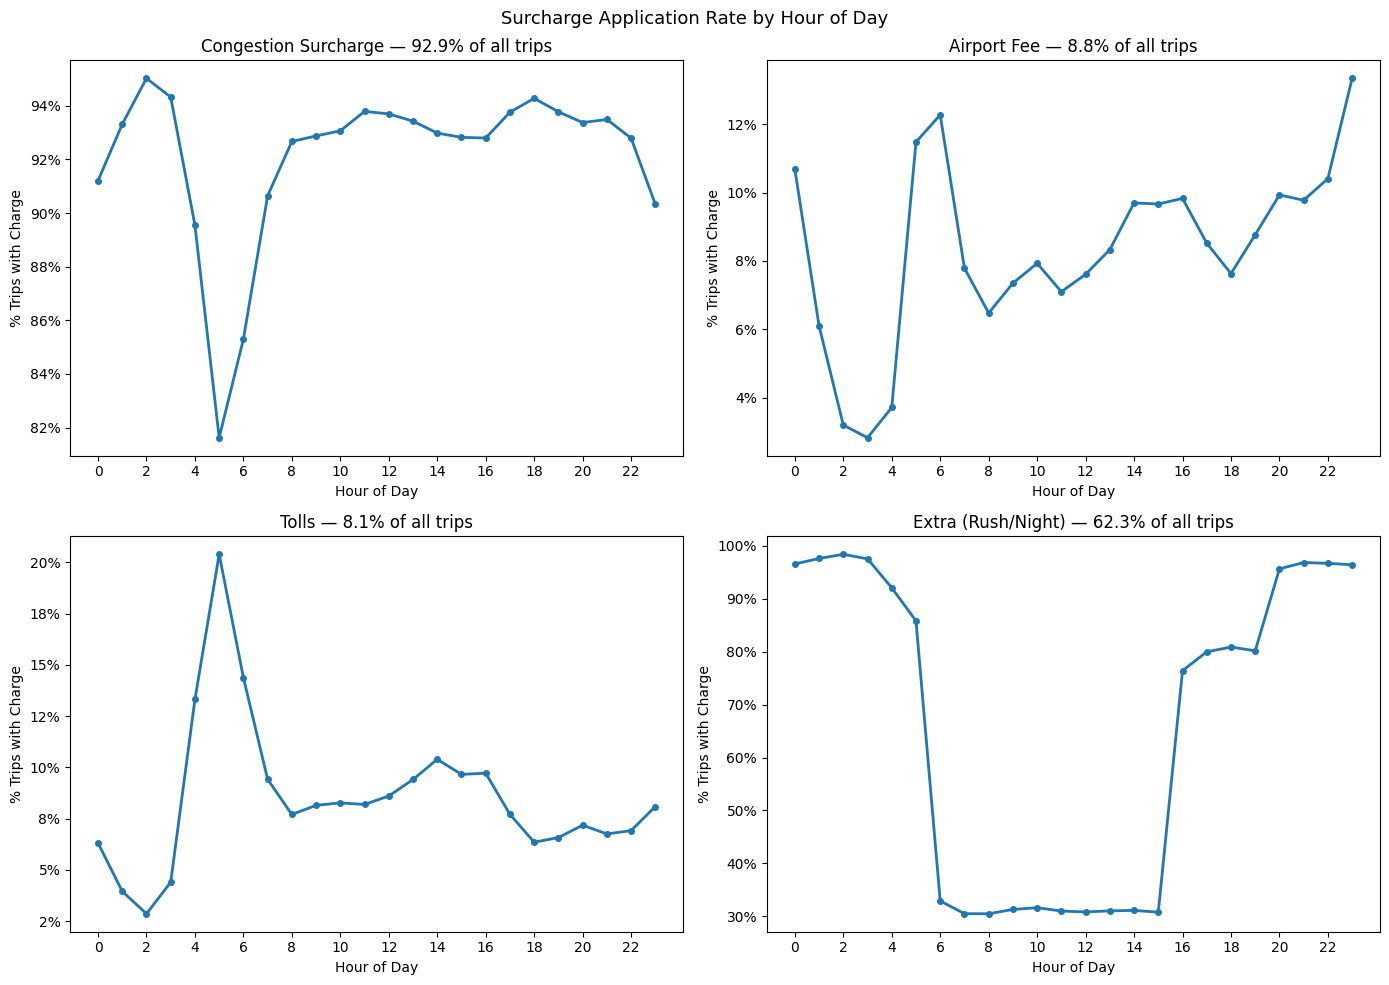

Overall surcharge prevalence:
  Congestion Surcharge     : 92.9% of trips
  Airport Fee              : 8.8% of trips
  Tolls                    : 8.1% of trips
  Extra (Rush/Night)       : 62.3% of trips

Zones with highest airport fee rate (top 5):
                            zone  airport_fee_percentage
               LaGuardia Airport                   98.40
                     JFK Airport                   93.60
                   East Elmhurst                   67.60
Saint Michaels Cemetery/Woodside                   12.50
                    Baisley Park                   10.60


In [81]:
# How often is each surcharge applied?
# List of all surcharges
surcharge_cols = {
    'congestion_surcharge': 'Congestion Surcharge',
    'airport_fee'         : 'Airport Fee',
    'tolls_amount'        : 'Tolls',
    'extra'               : 'Extra (Rush/Night)'
}
# finding all relevant surcharges
prevalence = {label: (df[col] > 0).mean() * 100
              for col, label in surcharge_cols.items()}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, (col, label) in enumerate(surcharge_cols.items()):
    hourly_rate = df.groupby('hour_of_the_day').apply(
        lambda g, c=col: (g[c] > 0).mean() * 100
    )
    axes[idx].plot(hourly_rate.index, hourly_rate.values,
                   marker='o', linewidth=2, markersize=4)
    axes[idx].set_title(f'{label} — {prevalence[label]:.1f}% of all trips')
    axes[idx].set_xlabel('Hour of Day')
    axes[idx].set_ylabel('% Trips with Charge')
    axes[idx].set_xticks(range(0, 24, 2))
    axes[idx].yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f'{x:.0f}%')
    )

plt.suptitle('Surcharge Application Rate by Hour of Day', fontsize=13)
plt.tight_layout()
plt.show()

print('Overall surcharge prevalence:')
for label, pct in prevalence.items():
    print(f'  {label:25s}: {pct:.1f}% of trips')

# Which zones get hit with airport fee most often?
# airport fee occurance data is extracted
airport_fee_occurrence_data = (
    df.groupby('PULocationID')
    .apply(lambda group_data: (group_data['airport_fee'] > 0).mean() * 100)
    .reset_index()
)
# getting location ids
airport_fee_occurrence_data.columns = ['LocationID', 'airport_fee_percentage']

zones['LocationID'] = zones['LocationID'].astype(int)
airport_fee_occurrence_data['LocationID'] = airport_fee_occurrence_data['LocationID'].astype(int)
# merging with zones to get names and not id numbers
airport_zone_names_merged = airport_fee_occurrence_data.merge(zones[['LocationID', 'zone']], on='LocationID')
# top five
top_five_airport_zones = airport_zone_names_merged.nlargest(5, 'airport_fee_percentage')
top_five_airport_zones['airport_fee_percentage'] = top_five_airport_zones['airport_fee_percentage'].round(1)

print('\nZones with highest airport fee rate (top 5):')
print(top_five_airport_zones[['zone', 'airport_fee_percentage']].to_string(index=False))


## **4** Conclusion
<font color = red>[15 marks]</font> <br>

### **4.1** Final Insights and Recommendations
<font color = red>[15 marks]</font> <br>

Conclude your analyses here. Include all the outcomes you found based on the analysis.

Based on the insights, frame a concluding story explaining suitable parameters such as location, time of the day, day of the week etc. to be kept in mind while devising a strategy to meet customer demand and optimise supply.

**4.1.1** <font color = red>[5 marks]</font> <br>
Recommendations to optimize routing and dispatching based on demand patterns and operational inefficiencies

In [82]:
# ── 4.1.1 Routing and Dispatching Recommendations ────────────────────────
print("""
ROUTING AND DISPATCHING RECOMMENDATIONS
=========================================

1. Peak-hour fleet concentration (18:00-19:00)
   The busiest hour is 18:00 (~129k sampled / ~2.58M estimated annual trips).
   Pre-position vehicles in Midtown (zones 161, 237) and the Upper East/West
   Sides (zones 236, 162) by 17:00 to be ready for the evening surge.

2. Weekday vs weekend dispatch strategy
   Weekday demand peaks sharply at 18:00 (commuter pattern). Weekend demand
   is flatter and peaks at 17:00 with a longer plateau. Weekend dispatching
   should spread coverage more evenly rather than concentrating on one peak.

3. Slow-route avoidance during congestion hours
   Route analysis reveals very low average speeds on certain zone pairs
   during 17:00-19:00. Routing should flag these corridors as congested
   and suggest alternate zone pairs to reduce idle time.

4. Low-demand slot reallocation (04:00-05:00)
   Trips drop to their lowest volumes at this time. A skeleton fleet
   pre-positioned toward airport zones (132, 138) would capture
   early-morning airport runs more efficiently.
""")


ROUTING AND DISPATCHING RECOMMENDATIONS

1. Peak-hour fleet concentration (18:00-19:00)
   The busiest hour is 18:00 (~129k sampled / ~2.58M estimated annual trips).
   Pre-position vehicles in Midtown (zones 161, 237) and the Upper East/West
   Sides (zones 236, 162) by 17:00 to be ready for the evening surge.

2. Weekday vs weekend dispatch strategy
   Weekday demand peaks sharply at 18:00 (commuter pattern). Weekend demand
   is flatter and peaks at 17:00 with a longer plateau. Weekend dispatching
   should spread coverage more evenly rather than concentrating on one peak.

3. Slow-route avoidance during congestion hours
   Route analysis reveals very low average speeds on certain zone pairs
   during 17:00-19:00. Routing should flag these corridors as congested
   and suggest alternate zone pairs to reduce idle time.

4. Low-demand slot reallocation (04:00-05:00)
   Trips drop to their lowest volumes at this time. A skeleton fleet
   pre-positioned toward airport zones (132, 138) 

**4.1.2** <font color = red>[5 marks]</font> <br>

Suggestions on strategically positioning cabs across different zones to make best use of insights uncovered by analysing trip trends across time, days and months.

In [83]:
# ── 4.1.2 Zone Positioning Strategy ─────────────────────────────────────
print("""
ZONE POSITIONING STRATEGY
===========================

1. High-pickup zones (zone 132 JFK, zone 138 LaGuardia)
   Both airport zones have very high pickup/dropoff ratios (4.6x and 2.9x).
   Drivers who drop off at airports rarely find return fares.
   Incentivise drivers to return to Midtown rather than queue at airports,
   or implement scheduled airport-return dispatch windows.

2. High-dropoff zones (zone 1 Newark, zone 257)
   These are trip sinks — cabs arrive but rarely find return fares.
   Avoid dispatching from these zones and assign drivers heading there
   only when a matching return ride is schedulable.

3. Night positioning (23:00-05:00)
   Zone 79 (East Village) leads night pickups, followed by zone 132 (JFK).
   Maintain a dedicated night cluster around zones 79, 48 (Lower East Side)
   and 249 (West Village) on Fridays and Saturdays.

4. Seasonal rebalancing
   May and October show the highest monthly revenues. Fleet capacity should
   expand slightly in these months (tourist season peaks) and contract in
   August and February.
""")


ZONE POSITIONING STRATEGY

1. High-pickup zones (zone 132 JFK, zone 138 LaGuardia)
   Both airport zones have very high pickup/dropoff ratios (4.6x and 2.9x).
   Drivers who drop off at airports rarely find return fares.
   Incentivise drivers to return to Midtown rather than queue at airports,
   or implement scheduled airport-return dispatch windows.

2. High-dropoff zones (zone 1 Newark, zone 257)
   These are trip sinks — cabs arrive but rarely find return fares.
   Avoid dispatching from these zones and assign drivers heading there
   only when a matching return ride is schedulable.

3. Night positioning (23:00-05:00)
   Zone 79 (East Village) leads night pickups, followed by zone 132 (JFK).
   Maintain a dedicated night cluster around zones 79, 48 (Lower East Side)
   and 249 (West Village) on Fridays and Saturdays.

4. Seasonal rebalancing
   May and October show the highest monthly revenues. Fleet capacity should
   expand slightly in these months (tourist season peaks) and co

**4.1.3** <font color = red>[5 marks]</font> <br>
Propose data-driven adjustments to the pricing strategy to maximize revenue while maintaining competitive rates with other vendors.

In [84]:
# ── 4.1.3 Pricing Strategy ───────────────────────────────────────────────
print("""
PRICING STRATEGY RECOMMENDATIONS
===================================

1. Short-trip pricing competitive with Vendor 1
   Vendor 2 averages $17.91/mile on short trips vs $9.93 for Vendor 1.
   For a new operator, pricing short trips closer to Vendor 1 makes the
   service more attractive. The gap narrows to ~$0.17/mile on longer trips
   so pricing parity there is less critical.

2. Dynamic pricing during high fare-per-mile hours
   Fare per mile peaks between 04:00-06:00 (airport runs) and 15:00-16:00.
   A modest surge multiplier (1.1x-1.2x) on these windows can increase
   revenue while remaining competitive with ride-hailing apps.

3. Group ride incentive
   Per-person cost falls steeply with group size. Marketing a flat
   group-fare product for 4-6 passengers could attract riders who
   currently use shared ride-pool services.

4. Tip nudge configuration
   Card tip % peaks at 17:00 (29.7%) and dips to ~23% in early morning.
   Configuring payment terminals to suggest 25/20/15% on evening trips
   (vs the standard 20/15/10%) can measurably increase average tips.

5. Night premium
   Night trips contribute only 12.1% of revenue despite 11.8% of trips.
   A small night surcharge beyond the existing 'extra' field would better
   reflect lower utilisation and higher per-trip operating cost at night.
""")


PRICING STRATEGY RECOMMENDATIONS

1. Short-trip pricing competitive with Vendor 1
   Vendor 2 averages $17.91/mile on short trips vs $9.93 for Vendor 1.
   For a new operator, pricing short trips closer to Vendor 1 makes the
   service more attractive. The gap narrows to ~$0.17/mile on longer trips
   so pricing parity there is less critical.

2. Dynamic pricing during high fare-per-mile hours
   Fare per mile peaks between 04:00-06:00 (airport runs) and 15:00-16:00.
   A modest surge multiplier (1.1x-1.2x) on these windows can increase
   revenue while remaining competitive with ride-hailing apps.

3. Group ride incentive
   Per-person cost falls steeply with group size. Marketing a flat
   group-fare product for 4-6 passengers could attract riders who
   currently use shared ride-pool services.

4. Tip nudge configuration
   Card tip % peaks at 17:00 (29.7%) and dips to ~23% in early morning.
   Configuring payment terminals to suggest 25/20/15% on evening trips
   (vs the standard 